In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Inherent Quantum Parallelism:

In a Quantum Computer, the same processor can perform operations on multiple inputs simultaneously and the state of a register can exist in a simultaneous superposition of different Quantum states.

The reason why quantum computation is different from classical computation is the fact that while a classical register can at a given time have or be in one state i.e., let us consider a simple classical bit and I have a one-bit register.

1. **`States and Superposition`**:

   - In classical computation, a **bit** in a register can exist in one of two states: `0` or `1`. For example, a **2-bit** register can represent one of the four classical states: `00`, `01`, `10`, or `11`.

   - In quantum computation, quantum bits or qubits can exist in a state of superposition. This means a qubit can represent both 0 and 1 simultaneously, in varying proportions. For instance, a 2-qubit quantum register can be in a linear combination of the classical states (00, 01, 10, 11) at the same time.

2. **`Superposition in Computation`**:

   - When performing computations on classical bits, you can only process `one state at a time`. If you have multiple inputs, you'd need `multiple processors or sequential operations` to compute the function for each input individually.

   - Quantum computation allows for computation on **superpositions**. This means when a function is applied to a quantum register in superposition, the computation is carried out on all the possible inputs simultaneously due to the nature of quantum parallelism. This inherent parallelism enables computations on multiple inputs at once, without the need for separate processors.

3. **`Parallelism`**:

   - In classical computing, parallelism is achieved by using `multiple processors`, where different processors handle different computations **concurrently**. This external parallelism involves dividing tasks among processors to speed up computation.
     
   - Quantum parallelism, on the other hand, `is inherent to the nature of qubits and superposition`. Quantum algorithms take advantage of this intrinsic property, allowing for computations on multiple states simultaneously without requiring additional hardware.

   - And the parallelism that we are talking about for a quantum computer is ***`inherent`***. And it is not outside parallelism which has trust in us by having several processors.

4. **` Measurement and Quantum Interference`**:

   - In quantum computation, after performing operations on a qubit or a quantum register, when a measurement is made, the superposition **collapses to a definite classical state**.
     
   - Quantum interference effects, resulting from the **superposition** and **manipulation of qubits**, allow for complex calculations, optimizations, and algorithms that exploit interference patterns among possible states to yield the desired output efficiently.
     
   - In other words, we compute the value of the function for each one of the inputs at the same time.

In summary, the fundamental difference between classical and quantum computation lies in the ability of qubits to exist in **superposition**, enabling computations on multiple inputs simultaneously through inherent quantum parallelism, *without relying on external parallel processing units*. This unique property forms the basis for the potential computational advantages of quantum computers for certain problems over classical computers.

# Quantum Algorithms:

## Deutsch-Jozsa:

The **Deutsch-Jozsa Algorithm** was one of the first quantum algorithms to demonstrate a clear advantage over classical computation.

The problem is to determine whether a black-box function (oracle)

$$
f:\{0,1\}^n \rightarrow \{0,1\}
$$

is:

1. **Constant**: Produces the same output for every input. $f(x)=0 \quad \forall x$ or $f(x)=1 \quad \forall x$

2. **Balanced**: Produces $0$ for exactly half of the inputs and $1$ for the other half.

The promise is that the function is either constant or balanced.


### Classical vs Quantum

For an $n$-bit function:

**Classical Algorithm :**

In the worst case, we must evaluate $2^{n-1}+1$ inputs to determine whether the function is constant or balanced.

**Quantum Algorithm :**

The Deutsch-Jozsa Algorithm determines the answer using **only one oracle query**.

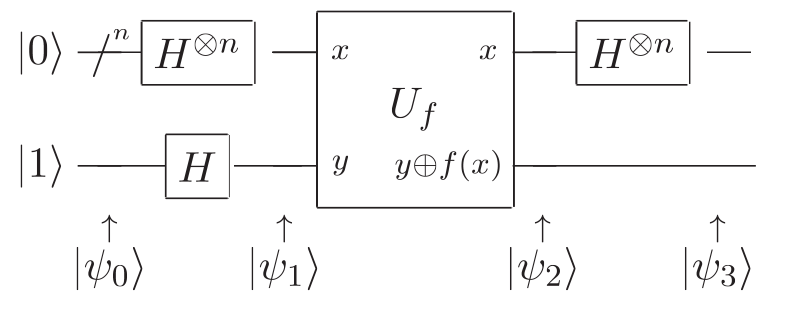

In [ ]:
from IPython.display import display, Image

img_path = "/content/drive/MyDrive/C-DAC FDP 2026 Resources/Day-4 (10th September)/Day4_lab-2/DJ_Block.png"

display(Image(filename=img_path, width=700))





### Algorithm Steps

For an $n$-bit function, we use

- $n$ input qubits

- $1$ ancilla qubit

Total qubits: $$n+1$$

#### Step 1: Initialize the Register

- Input qubits: $|0\rangle^{\otimes n}$

- Ancilla qubit: $|1\rangle$

Initial state:

$$\boxed{|\psi_0\rangle = |0\rangle^{\otimes n}|1\rangle}$$

#### Step 2: Apply Hadamard Gates

Apply Hadamard to all qubits.

- For the input register

$$H^{\otimes n}|0\rangle^{\otimes n}=\frac{1}{\sqrt{2^n}}\sum_x |x\rangle$$

- For the ancilla

$$H|1\rangle=\frac{|0\rangle-|1\rangle}{\sqrt2}=|-\rangle$$

Combined state:

$$\boxed{|\psi_1\rangle = \frac{1}{\sqrt{2^n}}\sum_x |x\rangle\otimes\frac{|0\rangle-|1\rangle}{\sqrt2}}$$


#### Step 3: Apply the Oracle

The oracle is represented as a unitary operator $U_f$ which is defined by $$U_f|x,y\rangle=|x,y\oplus f(x)\rangle$$ where, $\oplus$ denotes XOR.

The oracle performs

$$U_f|x\rangle|-\rangle=(-1)^{f(x)}|x\rangle|-\rangle$$

- The ancilla remains unchanged.

- The function value is encoded as a phase.

The resulting state becomes

$$\boxed{|\psi_2\rangle = \frac{1}{\sqrt{2^n}}\sum_x(-1)^{f(x)}|x\rangle|-\rangle}$$

This phenomenon is known as **Phase Kickback**.


#### Step 4: Apply Hadamard Gates Again

Apply $H^{\otimes n}$ to the input register. The resulting amplitudes interfere.

For one qubit:

$$H|0\rangle=\frac{|0\rangle+|1\rangle}{\sqrt2}$$

$$H|1\rangle=\frac{|0\rangle-|1\rangle}{\sqrt2}$$

For $n$ qubits:

$$H^{\otimes n}|x\rangle=\frac1{\sqrt{2^n}}\sum_{y=0}^{2^n-1}(-1)^{x\cdot y}|y\rangle$$

where $x\cdot y=x_0y_0\oplus x_1y_1\oplus ...\oplus x_{n-1}y_{n-1}$

- Substitute

$$|\psi_2\rangle=\frac1{\sqrt{2^n}}\sum_x(-1)^{f(x)}|x\rangle|-\rangle$$

- Apply $H^{\otimes n}$ to every basis state:

$$|\psi_3\rangle=\frac1{\sqrt{2^n}}\sum_x(-1)^{f(x)}H^{\otimes n}|x\rangle|-\rangle$$

- Substituting the Hadamard formula:

$$|\psi_3\rangle=\frac1{\sqrt{2^n}}\sum_x(-1)^{f(x)}\left(\frac1{\sqrt{2^n}}\sum_y(-1)^{x\cdot y}|y\rangle\right)|-\rangle$$

- Combining:

$$|\psi_3\rangle=\frac1{2^n}\sum_y\left[\sum_x(-1)^{f(x)+x\cdot y}\right]|y\rangle|-\rangle$$


#### Step 5: Measure

Measure only the first $n$ qubits.

- **If the function is Constant :** Constructive interference gives $|0\rangle^{\otimes n}$ with probability $1$. Measurement: $00\cdots0$

- **If the function is Balanced :** Destructive interference removes the amplitude of $|0\rangle^{\otimes n}$. Measurement is guaranteed to be something other than $00\cdots0$

To determine whether the function is constant or balanced, examine the amplitude of $|0\rangle^{\otimes n}$. For $y=0$ we have

$$
x\cdot y = 0
$$

- Therefore

$$A(0)=\frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)}$$

The probability of measuring $|0\rangle^{\otimes n}$ is

$$P(0)=|A(0)|^2=\left|\frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)}\right|^2$$


## Deutsch-Jozsa Algorithm Example

### Balanced Function: $f(x_0,x_1)=x_0 \oplus x_1$

Let us consider the balanced function

$$
f(x_0,x_1)=x_0\oplus x_1
$$

with truth table

| $x_0$ | $x_1$ | $f(x_0,x_1)$ |
|---------|---------|---------|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Since two outputs are 0 and two outputs are 1, the function is **Balanced**.

The oracle operation is

$$
U_f|x,y\rangle
=|x,y\oplus f(x)\rangle
$$



#### Step 1: Initialize the Registers

We use:

- Qubit 0 and Qubit 1 as input qubits
- Qubit 2 as ancilla qubit

Initial state:

$$
|\psi_0\rangle
=|00\rangle_{01}
\otimes
|1\rangle_2
$$

Statevector representation:

$$
|001\rangle
=\begin{bmatrix}
0\\
1\\
0\\
0\\
0\\
0\\
0\\
0
\end{bmatrix}
$$


#### Step 2: Apply Hadamard Gates

Apply Hadamard to all three qubits.

For the input register:

$$
H^{\otimes 2}|00\rangle
=\frac12
\Big(
|00\rangle
+
|01\rangle
+
|10\rangle
+
|11\rangle
\Big)
$$

For the ancilla:

$$
H|1\rangle
=\frac{|0\rangle-|1\rangle}{\sqrt2}
=|-\rangle
$$

Therefore

$$
|\psi_1\rangle
=\frac12
\Big(
|00\rangle
+
|01\rangle
+
|10\rangle
+
|11\rangle
\Big)
\otimes
\frac{|0\rangle-|1\rangle}{\sqrt2}
$$


**Statevector:**

Expanding,

$$
|\psi_1\rangle
=\frac{1}{2\sqrt2}
\Big(
|000\rangle-|001\rangle
+|010\rangle-|011\rangle
+|100\rangle-|101\rangle
+|110\rangle-|111\rangle
\Big)
$$

**Matrix Form:**
$$
|\psi_1\rangle
=\frac{1}{2\sqrt2}
\begin{bmatrix}
1\\
-1\\
1\\
-1\\
1\\
-1\\
1\\
-1
\end{bmatrix}
$$


#### Step 3: Apply the Oracle

For XOR

$$
f(x_0,x_1)=x_0\oplus x_1
$$

The oracle can be implemented as

$$
U_f=CX_{02}CX_{12}
$$

because the ancilla flips whenever either input bit is 1.

Applying the oracle:

$$
U_f|x\rangle|-\rangle
=(-1)^{f(x)}
|x\rangle|-\rangle
$$

#### Calculate the Phase for Each Basis State

***For $|00\rangle$***

- $f(00)=0$

- Phase:$(-1)^0=+1$

- Contribution: $$(-1)^0|00\rangle|-\rangle$$


***For $|01\rangle$***

- $f(01)=1$

- Phase:$(-1)^1=-1$

- Contribution:$$-|01\rangle|-\rangle$$



***For $|10\rangle$***

- $f(10)=1$

- Phase: $(-1)^1=-1$

- Contribution:$$-|10\rangle|-\rangle$$



***For $|11\rangle$***

- $f(11)=0$

- Phase:$(-1)^0=+1$

- Contribution:$$+|11\rangle|-\rangle$$


Therefore

$$|\psi_2\rangle=\frac12\Big(|00\rangle-|01\rangle-|10\rangle+|11\rangle\Big)\otimes|-\rangle$$

**Statevector:**

Expanding:

$$
|\psi_2\rangle
=\frac{1}{2\sqrt2}
\Big(
|000\rangle-|001\rangle
-|010\rangle+|011\rangle
-|100\rangle+|101\rangle
+|110\rangle-|111\rangle
\Big)
$$


**Matrix Form**

$$
|\psi_2\rangle
=\frac{1}{2\sqrt2}
\begin{bmatrix}
1\\
-1\\
-1\\
1\\
-1\\
1\\
1\\
-1
\end{bmatrix}
$$


#### Step 4: Factor the Input Register

Observe:

$$
|00\rangle
-|01\rangle
-|10\rangle
+|11\rangle
$$

can be factorized as

$$
(|0\rangle-|1\rangle)
\otimes
(|0\rangle-|1\rangle)
$$

- Therefore $$|\psi_2\rangle=\frac1{\sqrt2}(|0\rangle-|1\rangle)\otimes\frac1{\sqrt2}(|0\rangle-|1\rangle)\otimes|-\rangle$$ or $$|\psi_2\rangle=|-\rangle\otimes
|-\rangle\otimes|-\rangle$$


#### Step 5: Apply Hadamard Gates Again

Recall

$$
H|-\rangle
=|1\rangle
$$

Therefore

$$
H^{\otimes2}
\Big(
|-\rangle
\otimes
|-\rangle
\Big)
=|11\rangle
$$

Thus

$$
|\psi_3\rangle
=|11\rangle
\otimes
|-\rangle
$$


**Statevector:**

$$
|\psi_3\rangle
=|11\rangle
\otimes
\frac{|0\rangle-|1\rangle}{\sqrt2}
$$

$$
=\frac1{\sqrt2}
\Big(
|110\rangle
-|111\rangle
\Big)
$$

**Matrix Form**

$$
|\psi_3\rangle
=\frac1{\sqrt2}
\begin{bmatrix}
0\\
0\\
0\\
0\\
0\\
0\\
1\\
-1
\end{bmatrix}
$$

#### Step 6: Measure the Input Register

The first two qubits are $|11\rangle$. Therefore, the measurement outcome is $11$.

- Since the result is **not** $00$ the Deutsch-Jozsa decision rule says $\boxed{\text{Balanced Function}}$

### Constant Function: $f(x_0,x_1)=0$

Let us consider the constant function

$$
f(x_0,x_1)=0
$$ with truth table

| $x_0$ | $x_1$ | $f(x_0,x_1)$ |
| ----- | ----- | ------------ |
| 0     | 0     | 0            |
| 0     | 1     | 0            |
| 1     | 0     | 0            |
| 1     | 1     | 0            |

- Since all four inputs produce the same output $0$, the function is **Constant**.

- The oracle operation is  $$U_f|x,y\rangle=|x,y\oplus f(x)\rangle$$

- Since $f(x_0,x_1)=0,$ the oracle becomes $$U_f|x,y\rangle=|x,y\oplus0\rangle=|x,y\rangle$$

- Therefore, the constant-$0$ oracle does **nothing** to the qubits.

#### Step 1: Initialize the Registers

We use:

- Qubit $0$ and Qubit $1$ as input qubits

- Qubit $2$ as ancilla qubit

- Initial state: $$
|\psi_0\rangle=|00\rangle_{01}\otimes|1\rangle_2
$$

- Therefore, $$
|\psi_0\rangle=|001\rangle
$$

**Statevector representation:**

$$
|\psi_0\rangle
=\begin{bmatrix}
0\\
1\\
0\\
0\\
0\\
0\\
0\\
0
\end{bmatrix}
$$

#### Step 2: Apply Hadamard Gates

- Apply Hadamard gates to all three qubits. For the input register, $$H^{\otimes2}|00\rangle=\frac12\Big(|00\rangle+|01\rangle+|10\rangle+|11\rangle\Big)$$

- For the ancilla, $$H|1\rangle=\frac{|0\rangle-|1\rangle}{\sqrt2}=|-\rangle$$

- Therefore, $$|\psi_1\rangle = \frac12\Big(|00\rangle+|01\rangle+|10\rangle+|11\rangle\Big)\otimes|-\rangle$$

**Statevector:**

$$
|\psi_1\rangle=\frac{1}{2\sqrt2}\Big(|000\rangle-|001\rangle+|010\rangle-|011\rangle+|100\rangle-|101\rangle+|110\rangle-|111\rangle\Big)
$$

**Matrix Form:**

$$
|\psi_1\rangle=\frac{1}{2\sqrt2}\begin{bmatrix}1\\-1\\1\\-1\\1\\-1\\1\\-1\end{bmatrix}
$$

#### Step 3: Apply the Oracle

- For the constant function, $f(x_0,x_1)=0$ and therefore,
$$
U_f|x\rangle|-\rangle=(-1)^{f(x)}|x\rangle|-\rangle
$$

- Since $f(x)=0,$ we have $(-1)^0=1$ for every input state. Therefore, $$U_f|x\rangle|-\rangle=|x\rangle|-\rangle$$ for all four possible inputs.

- The oracle does not introduce any phase changes.

- Hence, $$|\psi_2\rangle=|\psi_1\rangle$$

- Therefore, $$|\psi_2\rangle=\frac12\Big(|00\rangle+|01\rangle+|10\rangle+|11\rangle\Big)\otimes|-\rangle$$

**Statevector:**

$$
|\psi_2\rangle
=\frac{1}{2\sqrt2}
\begin{bmatrix}
1\\
-1\\
1\\
-1\\
1\\
-1\\
1\\
-1
\end{bmatrix}
$$

#### Step 4: Factor the Input Register

- The input part can be written as $|00\rangle+|01\rangle+|10\rangle+|11\rangle$ which can be factorized as
$$
(|0\rangle+|1\rangle)
\otimes
(|0\rangle+|1\rangle)
$$

- Therefore, $$|\psi_2\rangle=\frac1{\sqrt2}(|0\rangle+|1\rangle)\otimes\frac1{\sqrt2}(|0\rangle+|1\rangle)\otimes|-\rangle$$ or $$\boxed{|\psi_2\rangle=|+\rangle\otimes|+\rangle\otimes|-\rangle}$$ where $$|+\rangle=\frac{|0\rangle+|1\rangle}{\sqrt2}$$


#### Step 5: Apply Hadamard Gates Again

- Recall that $H|+\rangle=|0\rangle$

- Therefore, $$
H^{\otimes2}
\Big(
|+\rangle\otimes|+\rangle
\Big)
=|00\rangle
$$

- The ancilla remains in $$
|-\rangle.
$$

- Thus, $$
|\psi_3\rangle
=|00\rangle\otimes|-\rangle
$$

- Therefore, $$
|\psi_3\rangle
=\frac1{\sqrt2}
\Big(
|000\rangle-|001\rangle
\Big)
$$

**Matrix Form:**

$$
|\psi_3\rangle
=\frac1{\sqrt2}
\begin{bmatrix}
1\\
-1\\
0\\
0\\
0\\
0\\
0\\
0
\end{bmatrix}
$$

#### Step 6: Measure the Input Register

- The first two qubits are in the state $$
|00\rangle
$$

- Therefore, measuring the input register gives $\boxed{00}$ with probability $1$.

- According to the Deutsch–Jozsa decision rule,

$$
\boxed{
00\cdots0
\Rightarrow
\text{Constant Function}
}
$$

- Therefore,

$$
\boxed{\text{The function }f(x_0,x_1)=0\text{ is Constant.}}
$$

## CODE for Deutsch-Jozsa:

In [ ]:
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# saved circuits for display

QC_ = None
C_ORACLE_ = None
B_ORACLE_ = None

backend = AerSimulator()

def constant_oracle (input_size, num_qubits):

    #Initialize first n qubits and single ancilla qubit
    qc = QuantumCircuit(num_qubits, name=f"Constant_Oracle")

    output = np.random.randint(2)

    if output == 1:
        qc.x(input_size)

    global C_ORACLE_
    if C_ORACLE_ == None or num_qubits <= 6:
        if num_qubits < 9: C_ORACLE_ = qc

    return qc

def balanced_oracle (input_size, num_qubits):
    #Initialize first n qubits and single ancilla qubit
    qc = QuantumCircuit(num_qubits, name=f"Balanced_Oracle")
    #b_str = "111111111111111100000000000000000"
    b_str = "101010101010101010101010101010101"              # permit input_string up to 20 chars
    for qubit in range(input_size):
        if b_str[qubit] == '1':
            qc.x(qubit)

    qc.barrier()

    for qubit in range(input_size):
        qc.cx(qubit, input_size)

    qc.barrier()

    for qubit in range(input_size):
        if b_str[qubit] == '1':
            qc.x(qubit)

    global B_ORACLE_
    if B_ORACLE_ == None or num_qubits <= 6:
        if num_qubits < 9: B_ORACLE_ = qc

    return qc

def DeutschJozsa (num_qubits, type):

    # Size of input is one less than available qubits
    input_size = num_qubits - 1

    # allocate qubits
    qr = QuantumRegister(num_qubits); cr = ClassicalRegister(input_size);
    qc = QuantumCircuit(qr, cr, name=f"dj-{num_qubits}-{type}")

    for qubit in range(input_size):
        qc.h(qubit)
    qc.x(input_size)
    qc.h(input_size)

    qc.barrier()

    # Add a constant or balanced oracle function
    if type == 0:
        Uf = constant_oracle(input_size, num_qubits)
    else:
        Uf = balanced_oracle(input_size, num_qubits)

    qc.compose(Uf, qubits=qr, inplace=True)

    qc.barrier()

    for qubit in range(num_qubits):
        qc.h(qubit)

    # uncompute ancilla qubit, not necessary for algorithm
    qc.x(input_size)

    qc.barrier()

    for i in range(input_size):
        qc.measure(i, i)

    # save smaller circuit and oracle subcircuit example for display
    global QC_
    if QC_ == None or num_qubits <= 6:
        if num_qubits < 9: QC_ = qc

    # return a handle to the circuit
    return qc,Uf

const,Const_Oracle = DeutschJozsa (num_qubits=3, type=0)
bal,Bal_Oracle = DeutschJozsa (num_qubits=3, type=1)

### Constant Oracle:

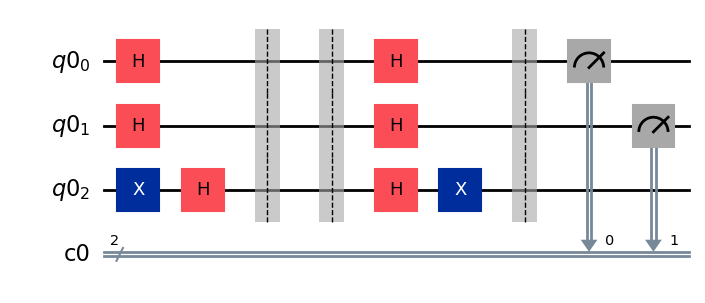

In [ ]:
from IPython.display import display, Math

#circuit with constant oracle
display(const.draw('mpl'))

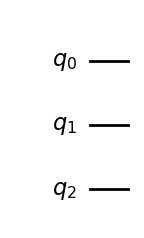

In [ ]:
#inside the constant oracle
Const_Oracle.draw('mpl')

In [ ]:
# execution
job =  backend.run(const, shots=1000)
result = job.result()
print(f"\n Probabilities :{result.get_counts()}")


 Probabilities :{'00': 1000}


### Balanced Oracle:

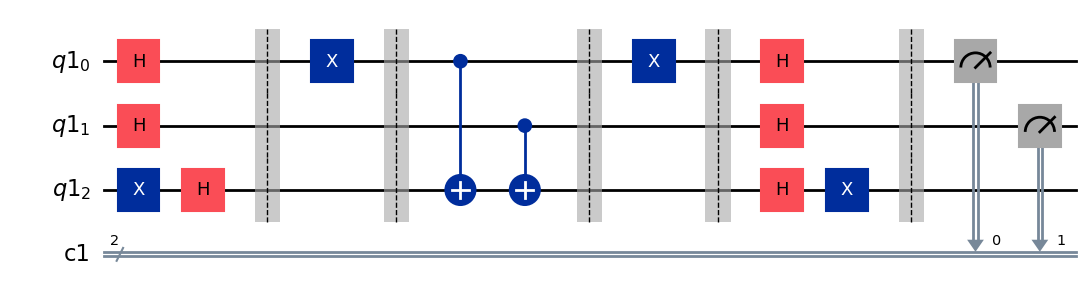

In [ ]:
#circuit with Balanced oracle
bal.draw('mpl')

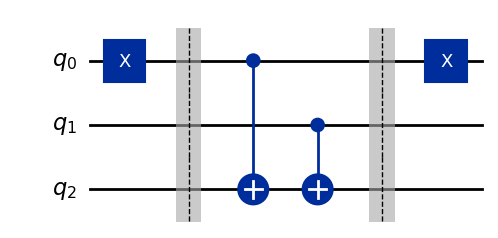

In [ ]:
#inside the Balanced oracle
Bal_Oracle.draw('mpl')

In [ ]:
# execution

job =  backend.run(bal, shots=1000)
result = job.result()
print(f"\n Probabilities :{result.get_counts()}")


 Probabilities :{'11': 1000}


## Grover's Search Algorithm:

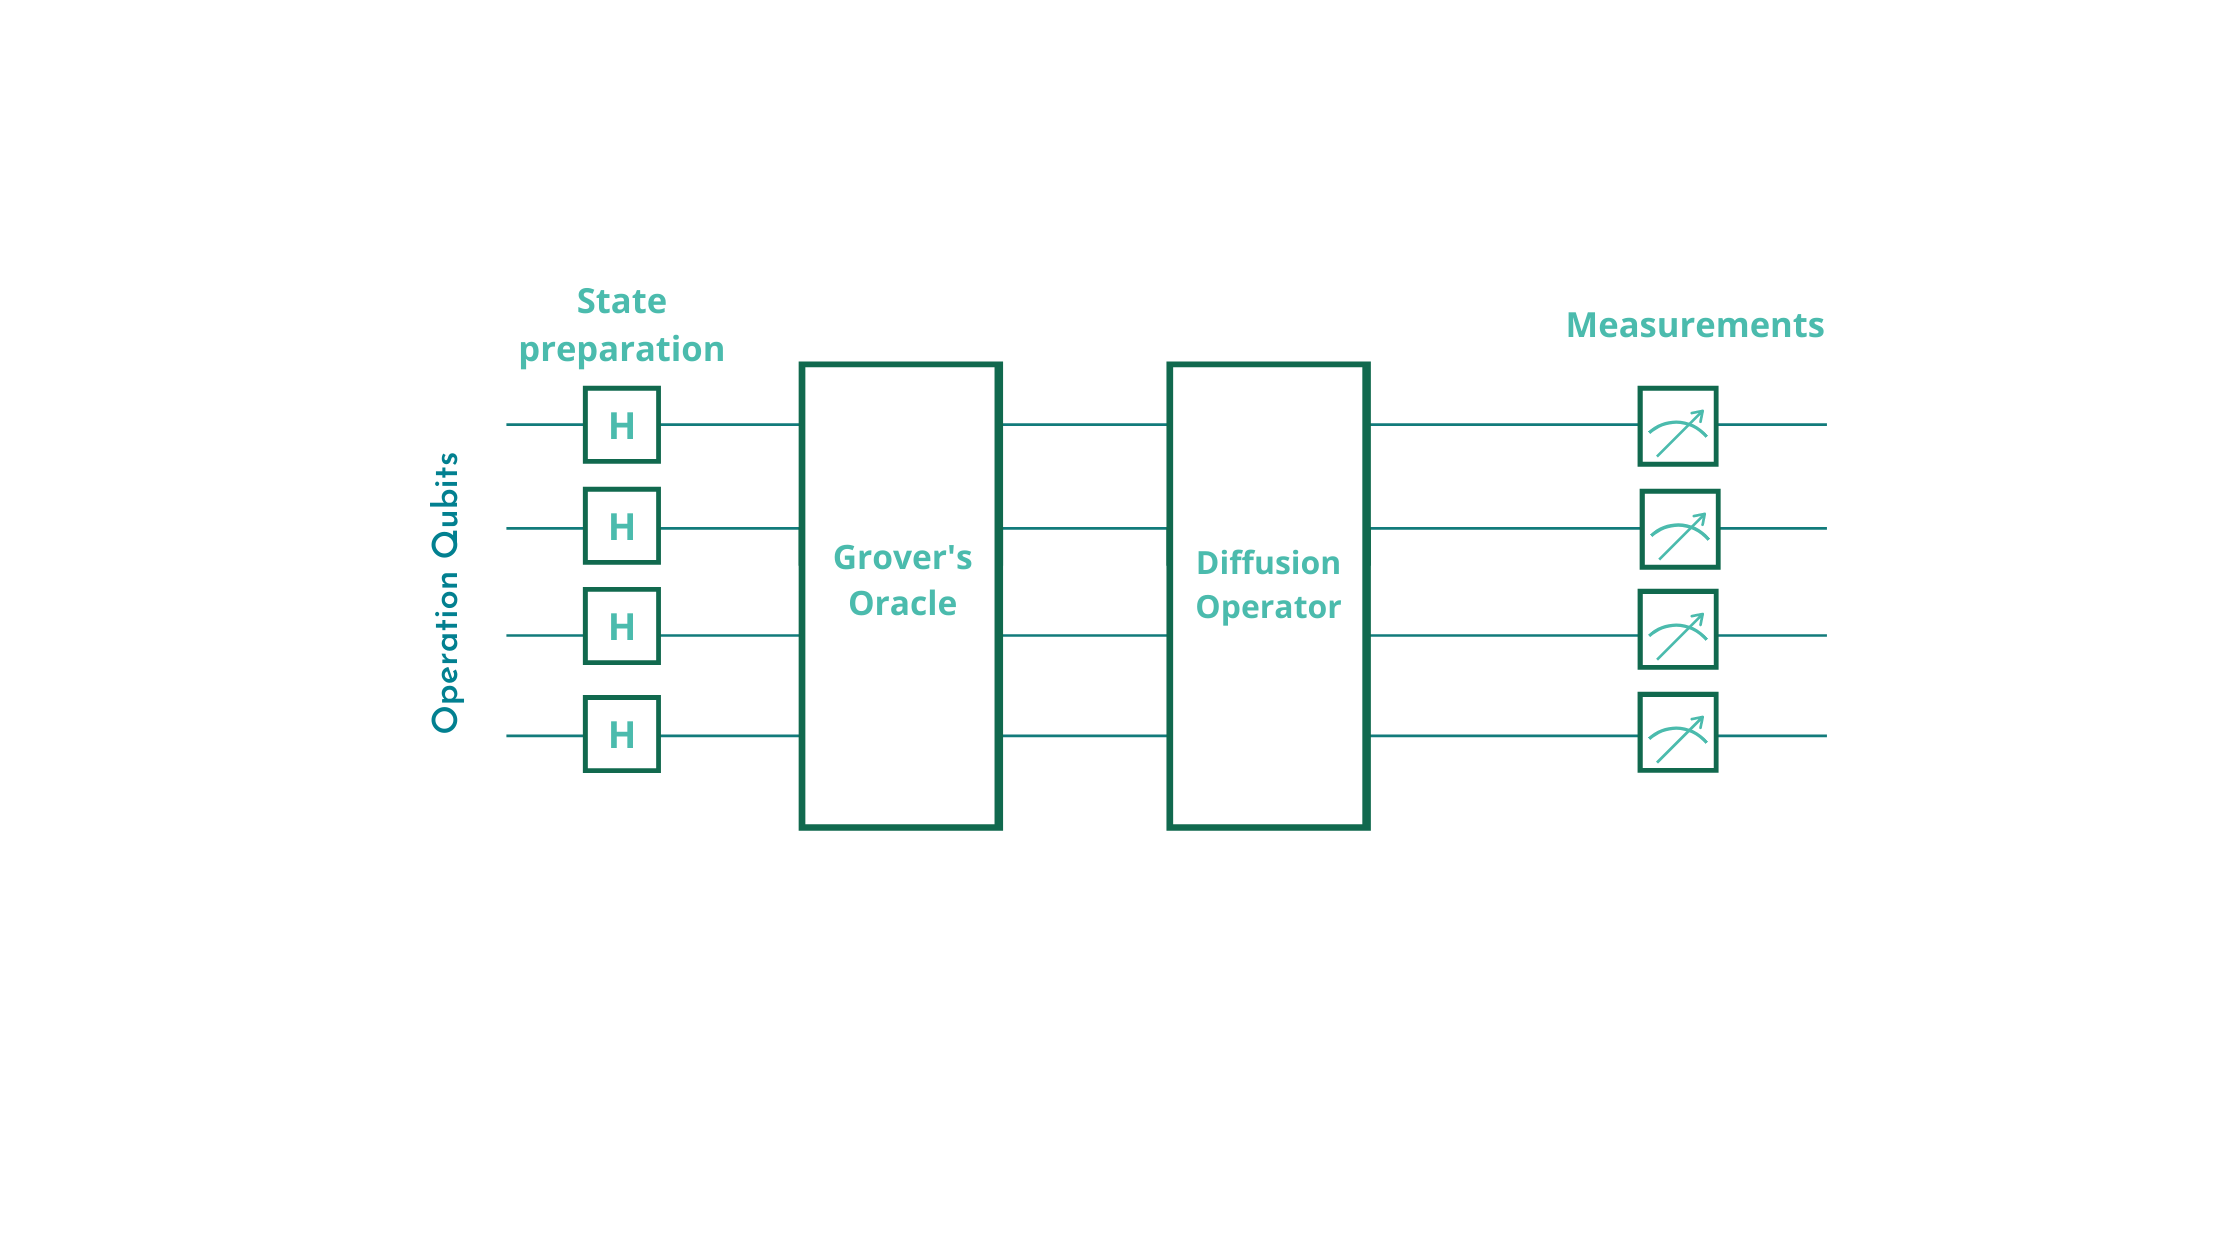

In [ ]:
from IPython.display import display, Image

img_path = "/content/drive/MyDrive/C-DAC FDP 2026 Resources/Day-4 (10th September)/Day4_lab-2/Grover's/grover_steps.png"

display(Image(filename=img_path, width=700))

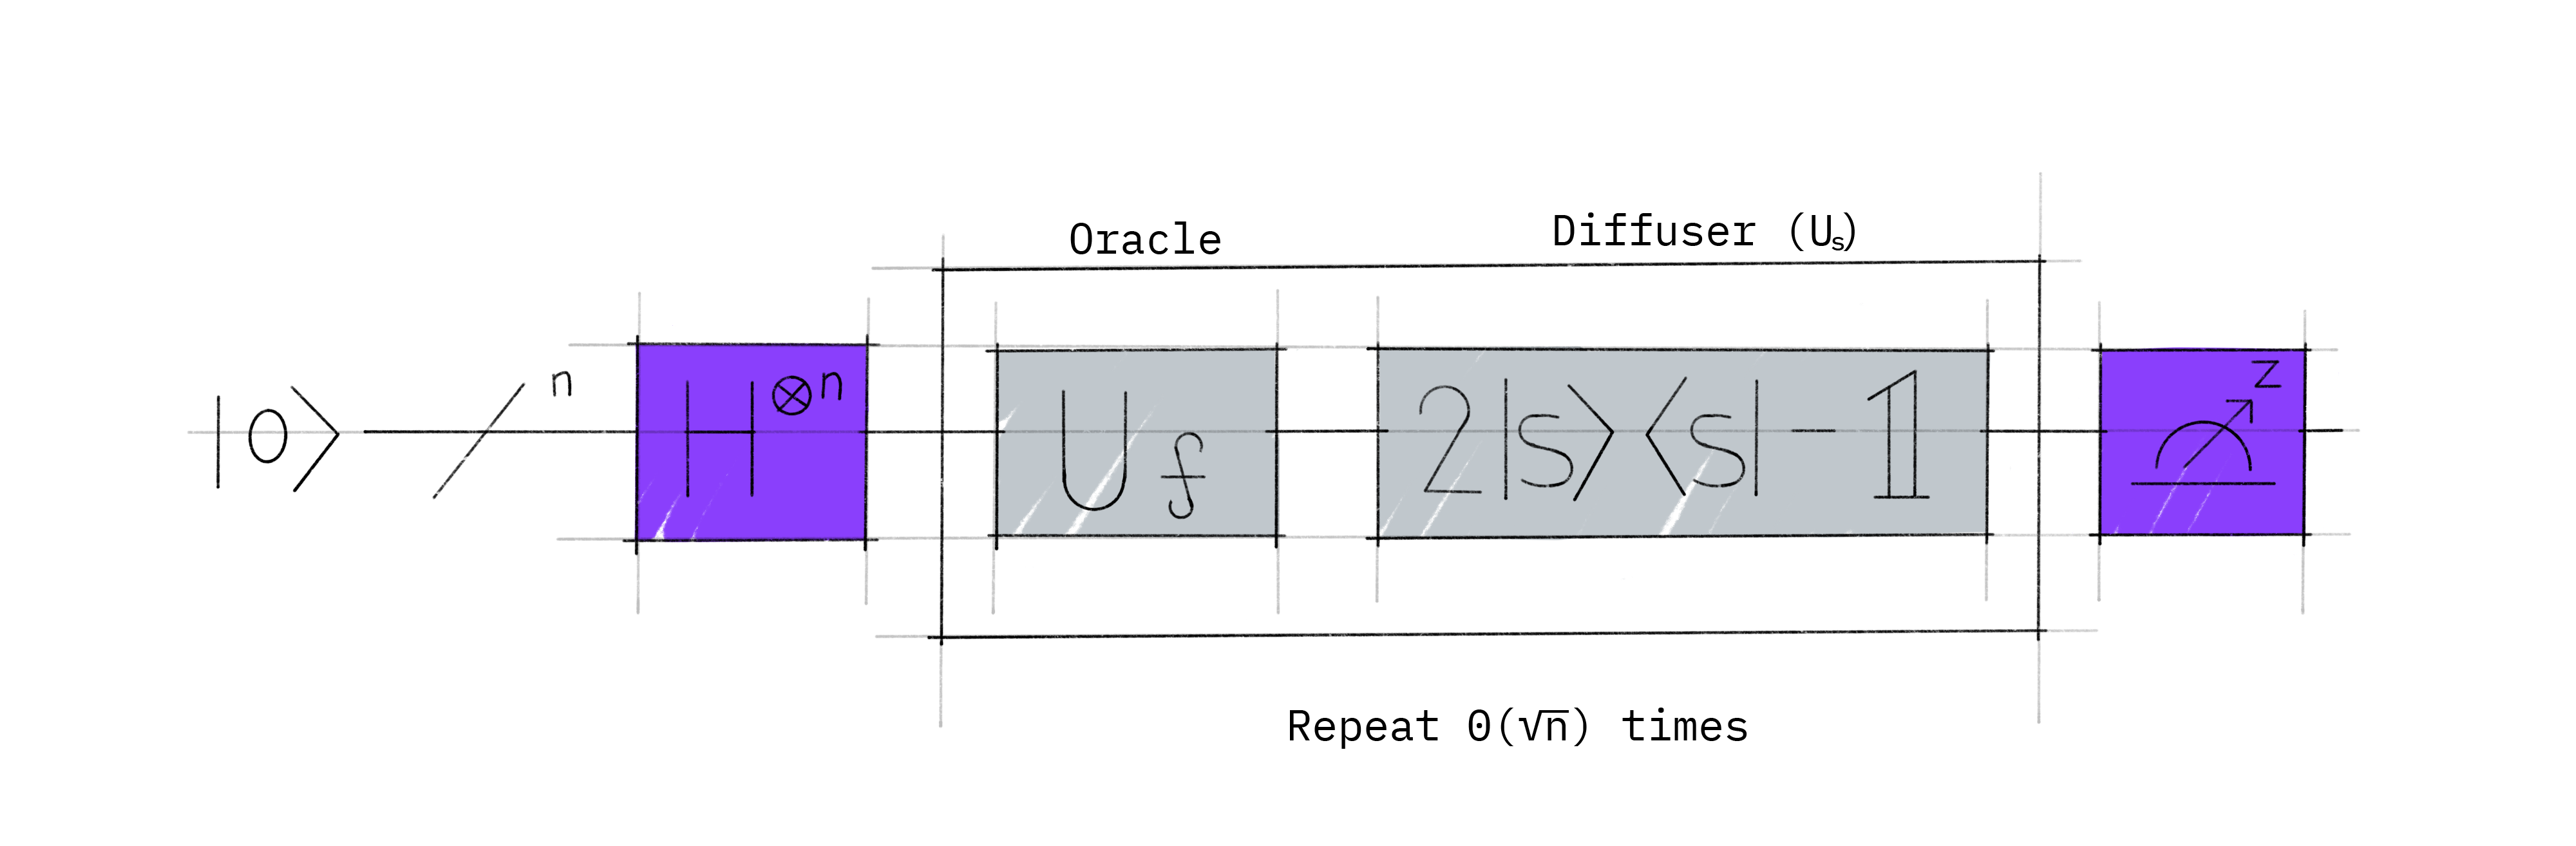



- One complete Grover iteration is $$G=D U_\omega$$ where $$ U_\omega \implies \textbf{oracle} $$

$$ D=2|s\rangle\langle s|-I \implies \textbf{diffusion operator}$$

### Two-Dimensional Geometry

Grover's algorithm can be understood as repeated rotations.

- Define

$$
\sin\theta
=\sqrt{\frac{M}{N}}
$$

where $M$ is the number of solutions.

- The initial state is

$$
|s\rangle
=\cos\theta |s'\rangle
+
\sin\theta |w\rangle
$$

- Each Grover iteration rotates the state by $2\theta$ toward $|w\rangle$.

- After $r$ iterations:

$$
G^r|s\rangle
=\cos((2r+1)\theta)|s'\rangle
+
\sin((2r+1)\theta)|w\rangle
$$

### Optimal Number of Iterations

- To maximize the probability of measuring a solution:

$$
(2r+1)\theta
\approx
\frac{\pi}{2}
$$

- Thus

$$
r
\approx
\frac{\pi}{4}
\sqrt{\frac{N}{M}}
$$

- For one marked state $M=1$:

$$ r \approx \frac{\pi}{4}\sqrt{N}$$





#### Three-Qubit Example

- Suppose $N=8$ and the marked state is

$$
|101\rangle
$$

- Then $M=1$ and

$$
\theta
=\sin^{-1}
\left(
\frac1{\sqrt8}
\right)
\approx
0.361
\text{ rad}
$$

- Optimal iterations:

$$
r
=\left\lfloor
\frac{\pi}{4}
\sqrt8
\right\rfloor
=2
$$

- Thus two Grover iterations are sufficient.

In [ ]:
from IPython.display import display, Image

img_path = "/content/drive/MyDrive/C-DAC FDP 2026 Resources/Day-4 (10th September)/Day4_lab-2/Grover's/Grover_Iterations.gif"

display(Image(filename=img_path, width=700))

Output hidden; open in https://colab.research.google.com to view.

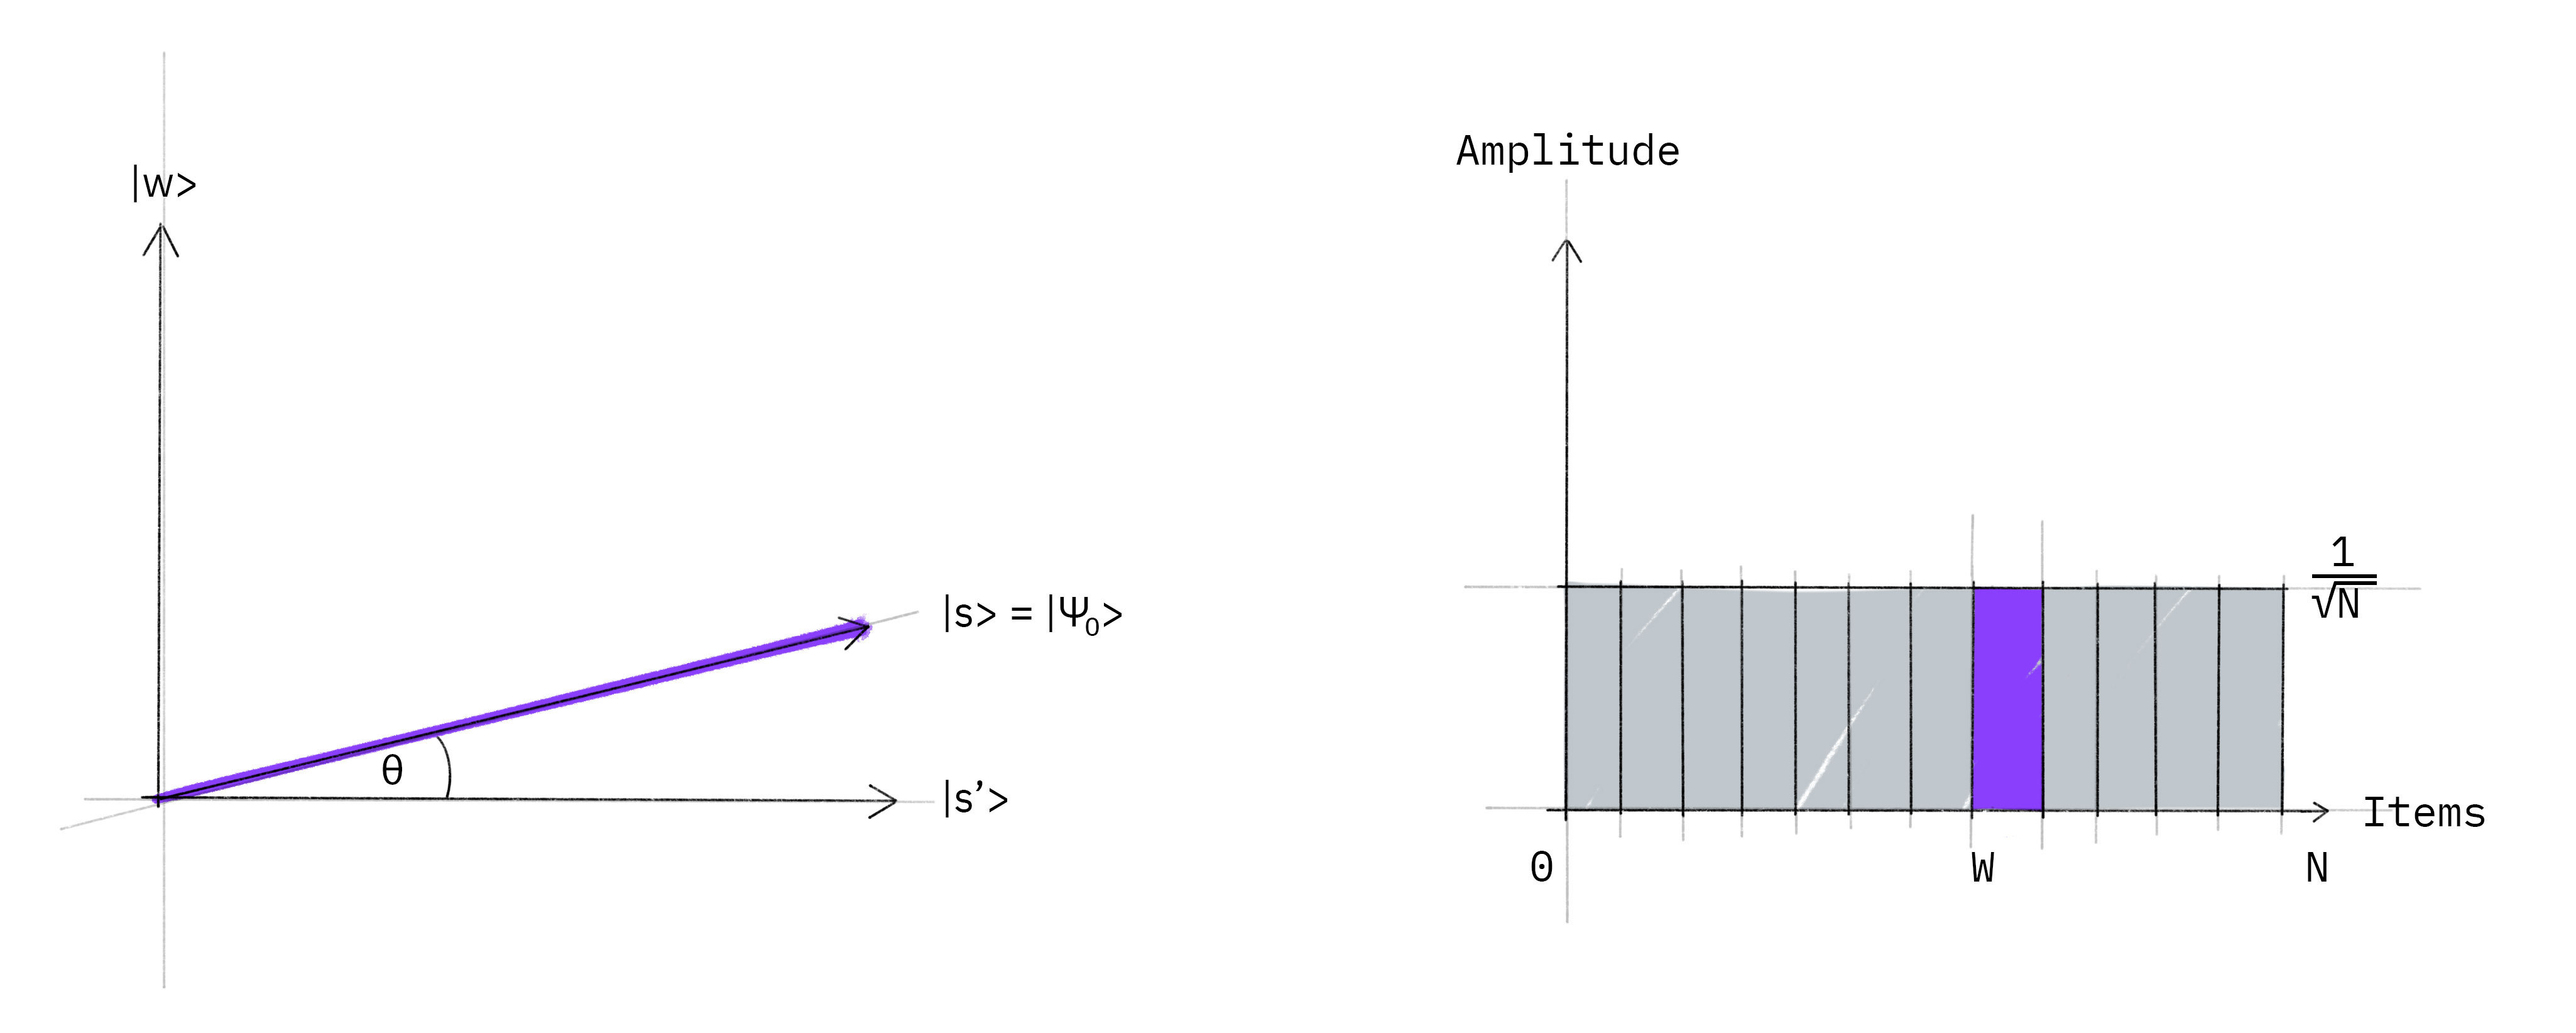

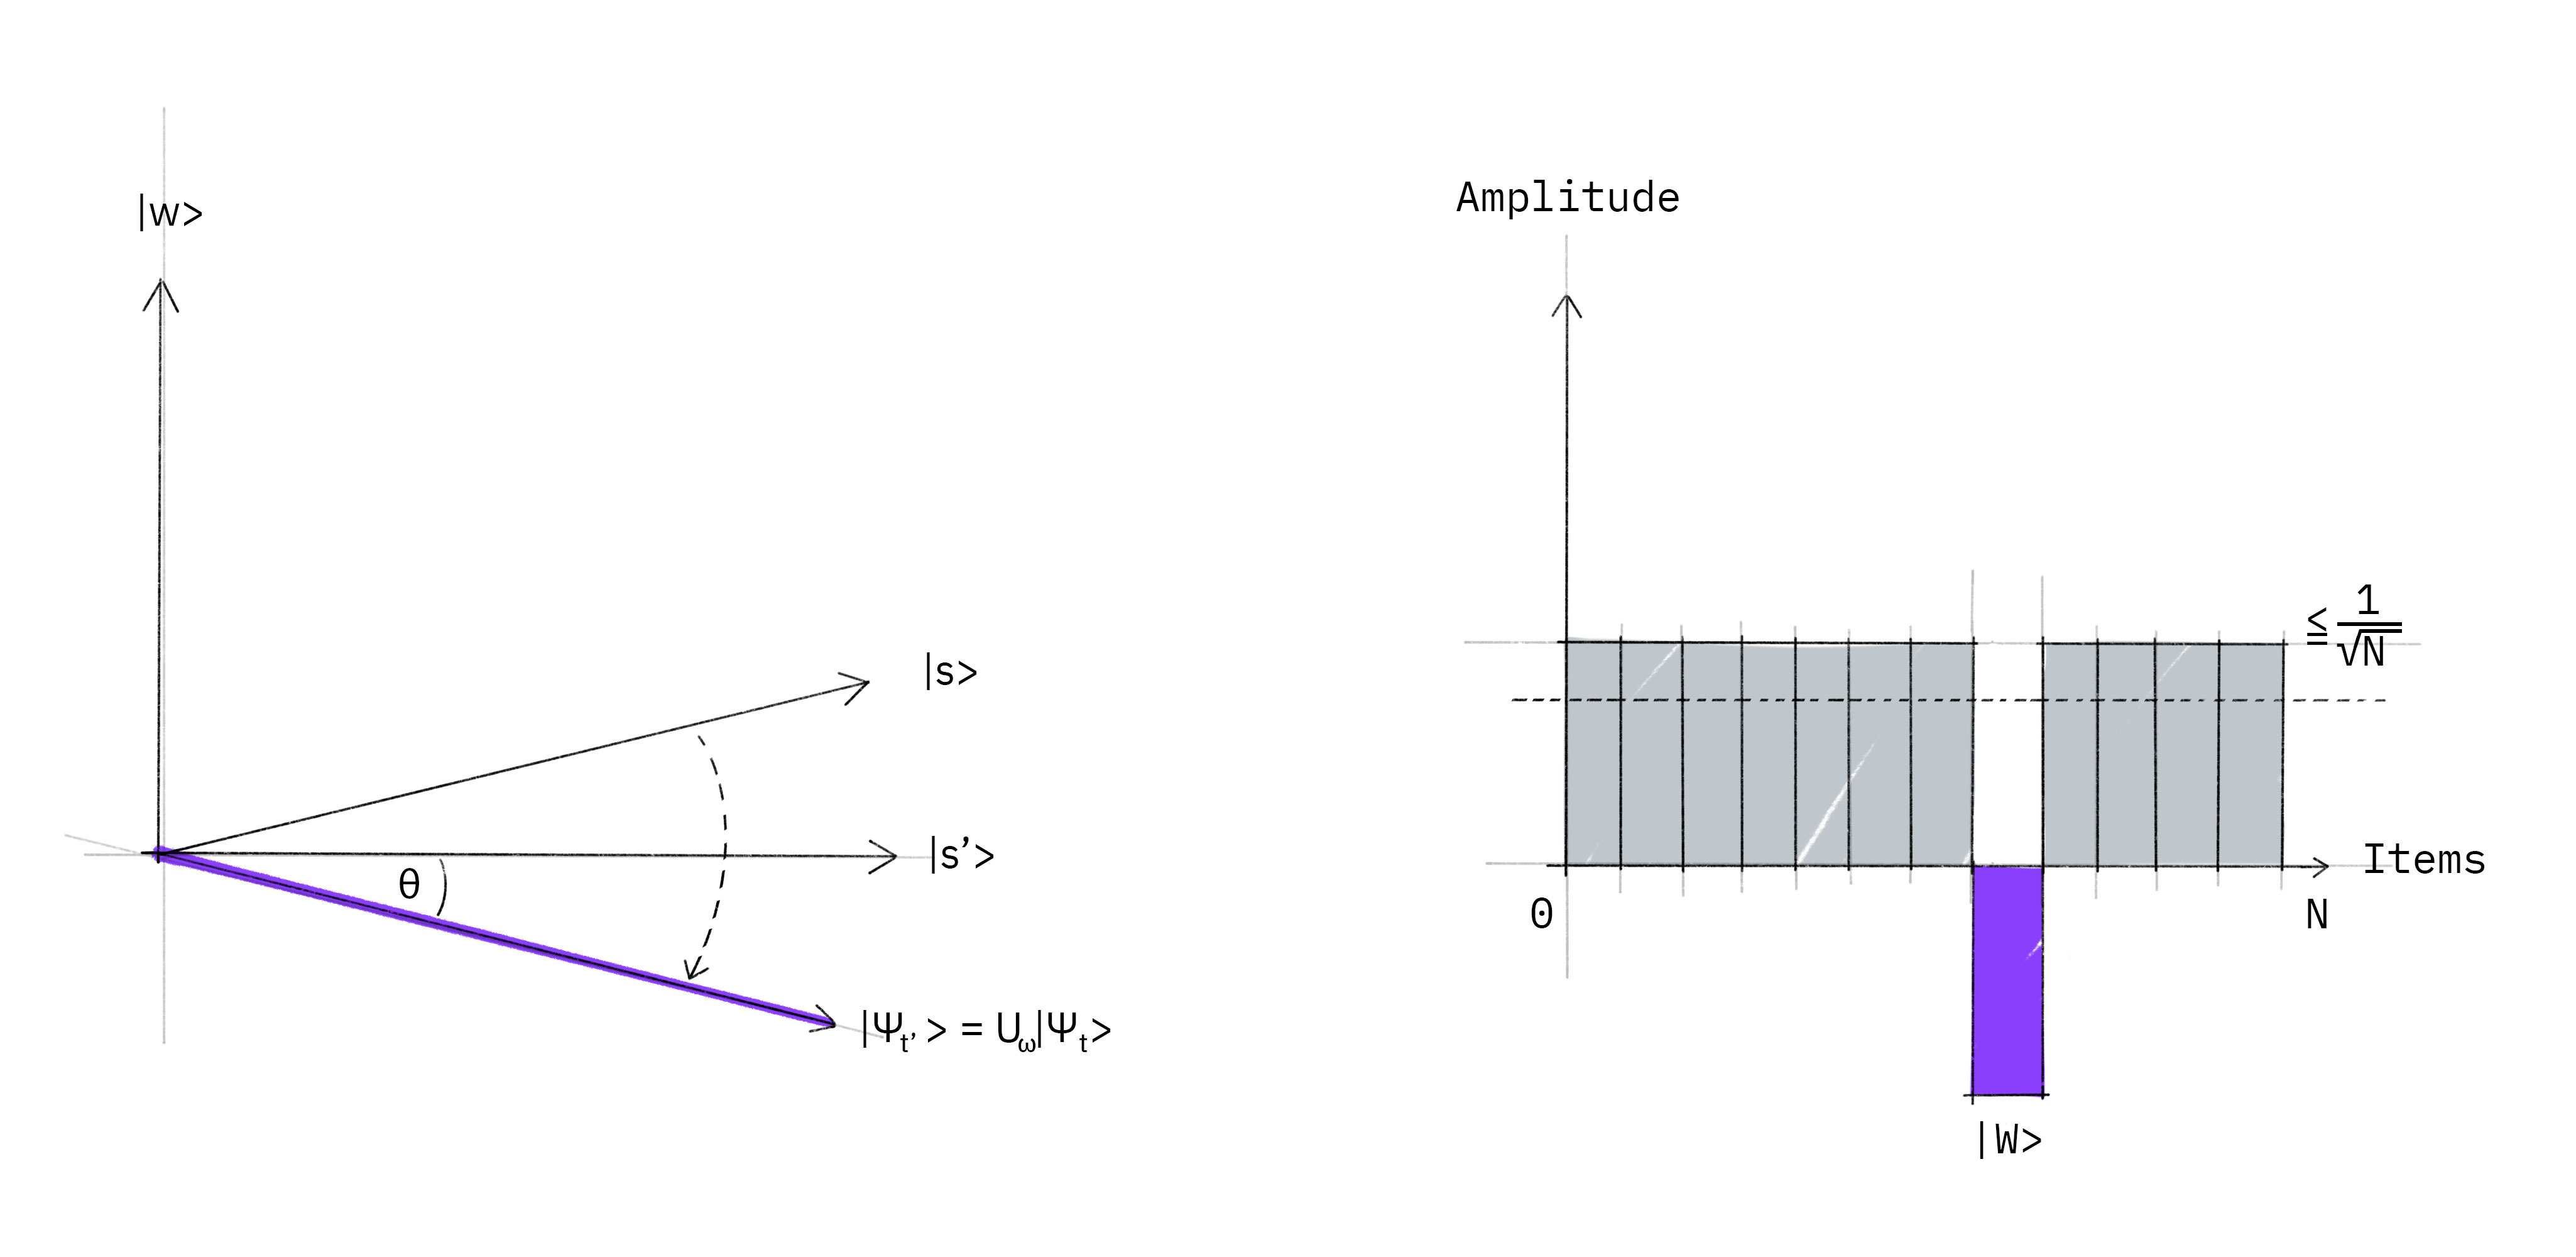

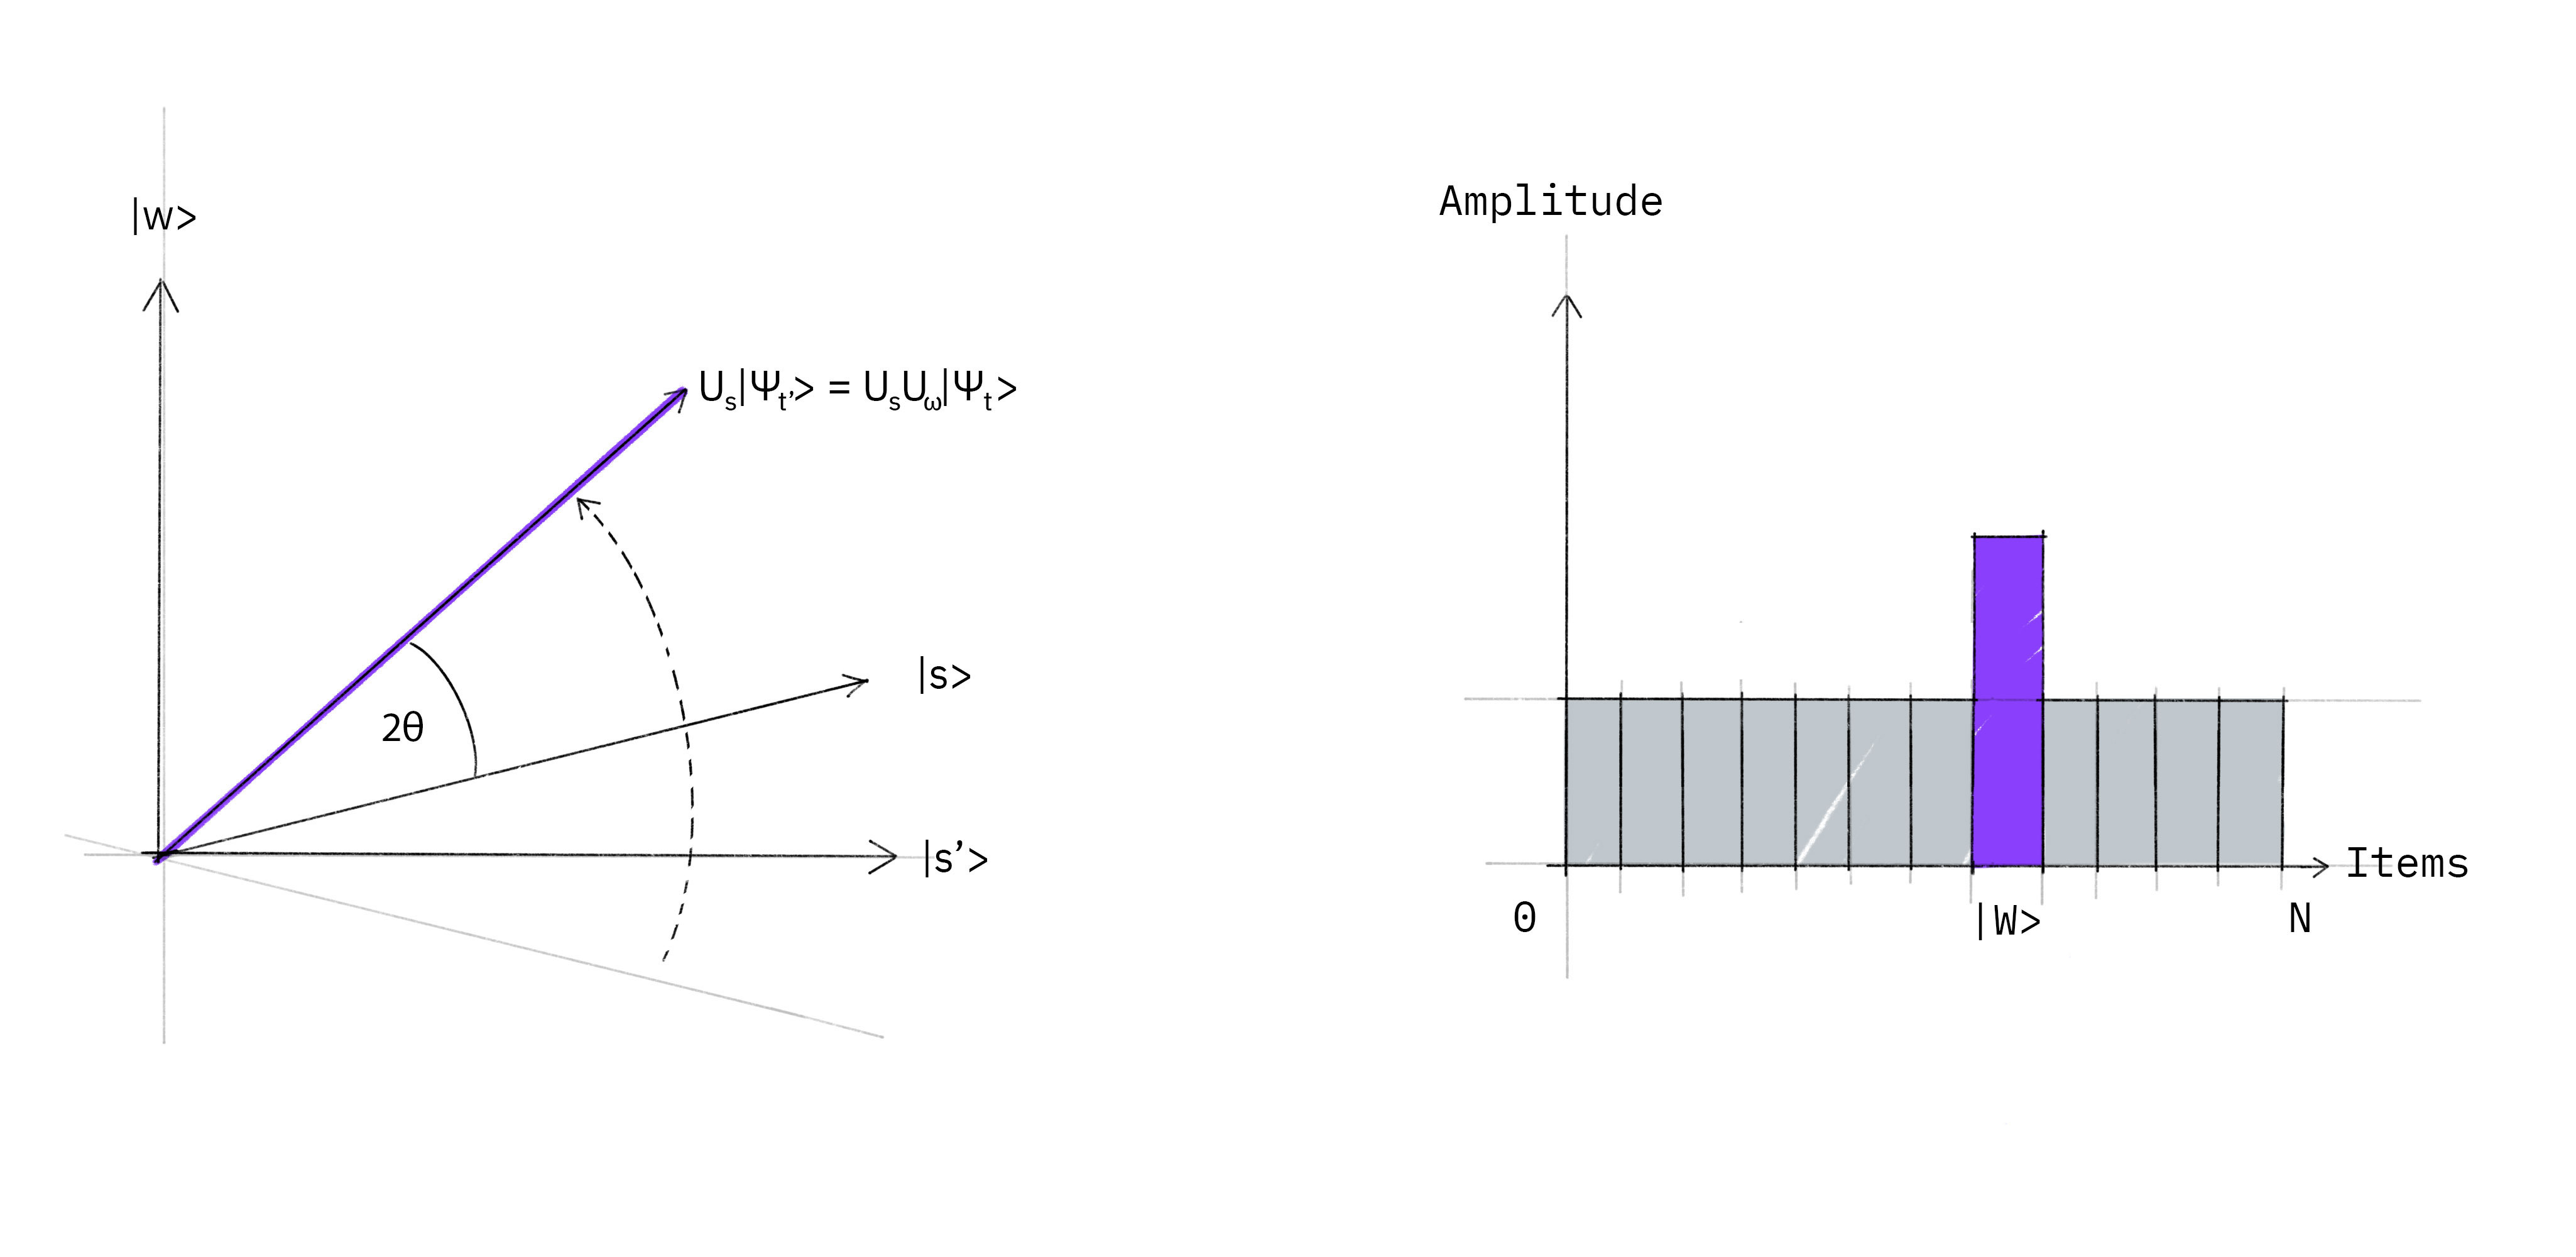

## Circuit Structure:

The complete Grover Search circuit consists of three major components:

1. **Initialization Circuit**

2. **Grover Oracle**

3. **Diffusion Operator (Amplitude Amplification)**

### 1. Overall Grover Search Circuit

The circuit structure is:

```text
|0⟩ ──H──── Oracle ── Diffuser ── Oracle ── Diffuser ── ... ── Measure
|0⟩ ──H──── Oracle ── Diffuser ── Oracle ── Diffuser ── ... ── Measure
|0⟩ ──H──── Oracle ── Diffuser ── Oracle ── Diffuser ── ... ── Measure
```

where:

- The initial Hadamard gates create a uniform superposition.

- The Oracle marks the target state.

- The Diffuser amplifies the marked state's probability.

- The Oracle + Diffuser pair forms one **Grover Iteration**.


```python
GroversSearch(num_qubits, marked_item, n_iterations)
```

- The Grover operator is $$G = D,O$$

- After $k$ iterations,

$$
|\psi_k\rangle
=(DO)^k
|s\rangle
$$

### 2. Initialization Circuit

The algorithm begins with

$$
|0\rangle^{\otimes n}
$$

- For example, for $3$ qubits: $$|000\rangle$$

- Applying Hadamard to every qubit:

```python
for i_qubit in range(num_qubits):
    qc.h(qr[i_qubit])
```

creates

$$
|s\rangle=H^{\otimes n}|0\rangle^{\otimes n} \implies
|s\rangle
=\frac1{\sqrt N}
\sum_{x=0}^{N-1}|x\rangle
$$ where $N=2^n$

- For 3 qubits:

$$
|s\rangle
=\frac1{\sqrt8}
(
|000\rangle+
|001\rangle+
|010\rangle+
|011\rangle+
|100\rangle+
|101\rangle+
|110\rangle+
|111\rangle
)
$$

At this stage every state has equal probability.

### 3. Grover Oracle

- The Oracle identifies the desired state and flips its phase.

- Mathematically: $$O=I-2|w\rangle\langle w|$$ where $|w\rangle$ is the marked state.

- The Oracle performs $$|w\rangle\rightarrow-|w\rangle$$ while leaving all other states unchanged.


#### Example

- Suppose the marked state is

$$
|101\rangle
$$

- The Oracle transforms

$$
\frac1{\sqrt8}
(
|000\rangle+
|001\rangle+
\cdots
+
|101\rangle
+
\cdots
+
|111\rangle
)
\rightarrow
\frac1{\sqrt8}
(
|000\rangle+
|001\rangle+
\cdots -
|101\rangle
+
\cdots
+
|111\rangle
)
$$

- Only the phase changes. The measurement probabilities remain unchanged.

#### Oracle can be implemented as:

- The marked state is converted into binary:

```python
marked_item_bits = format(marked_item,f"0{num_qubits}b")
```

- Example: $$\text{marked-item} = 5 \implies |101\rangle$$


**Step 1: Convert Target State into $|111\rangle$**

```python
for (q,bit) in enumerate(marked_item_bits):
    if not int(bit):
        qc.x(q)
```

- Any qubit containing $0$ is flipped.

- Example: Target state $|101\rangle$ becomes $$|111\rangle$$ after applying $X$ gates.

**Step 2: Phase Flip**

```python
qc.h(num_qubits-1)
qc.mcx(...)
qc.h(num_qubits-1)
```

- This sequence converts a **multi-controlled-X** gate into a **multi-controlled-Z** gate.

- Mathematically: $$H X H = Z$$

- Therefore the circuit performs $$|111\rangle\rightarrow-|111\rangle$$ which corresponds to $$|101\rangle\rightarrow-|101\rangle$$ in the original basis.

**Step 3: Undo the X Gates**

```python
for (q,bit) in enumerate(marked_item_bits):
    if not int(bit):
        qc.x(q)
```

- The basis transformation is reversed.

- The Oracle has now phase-marked only the desired state.


Earlier:

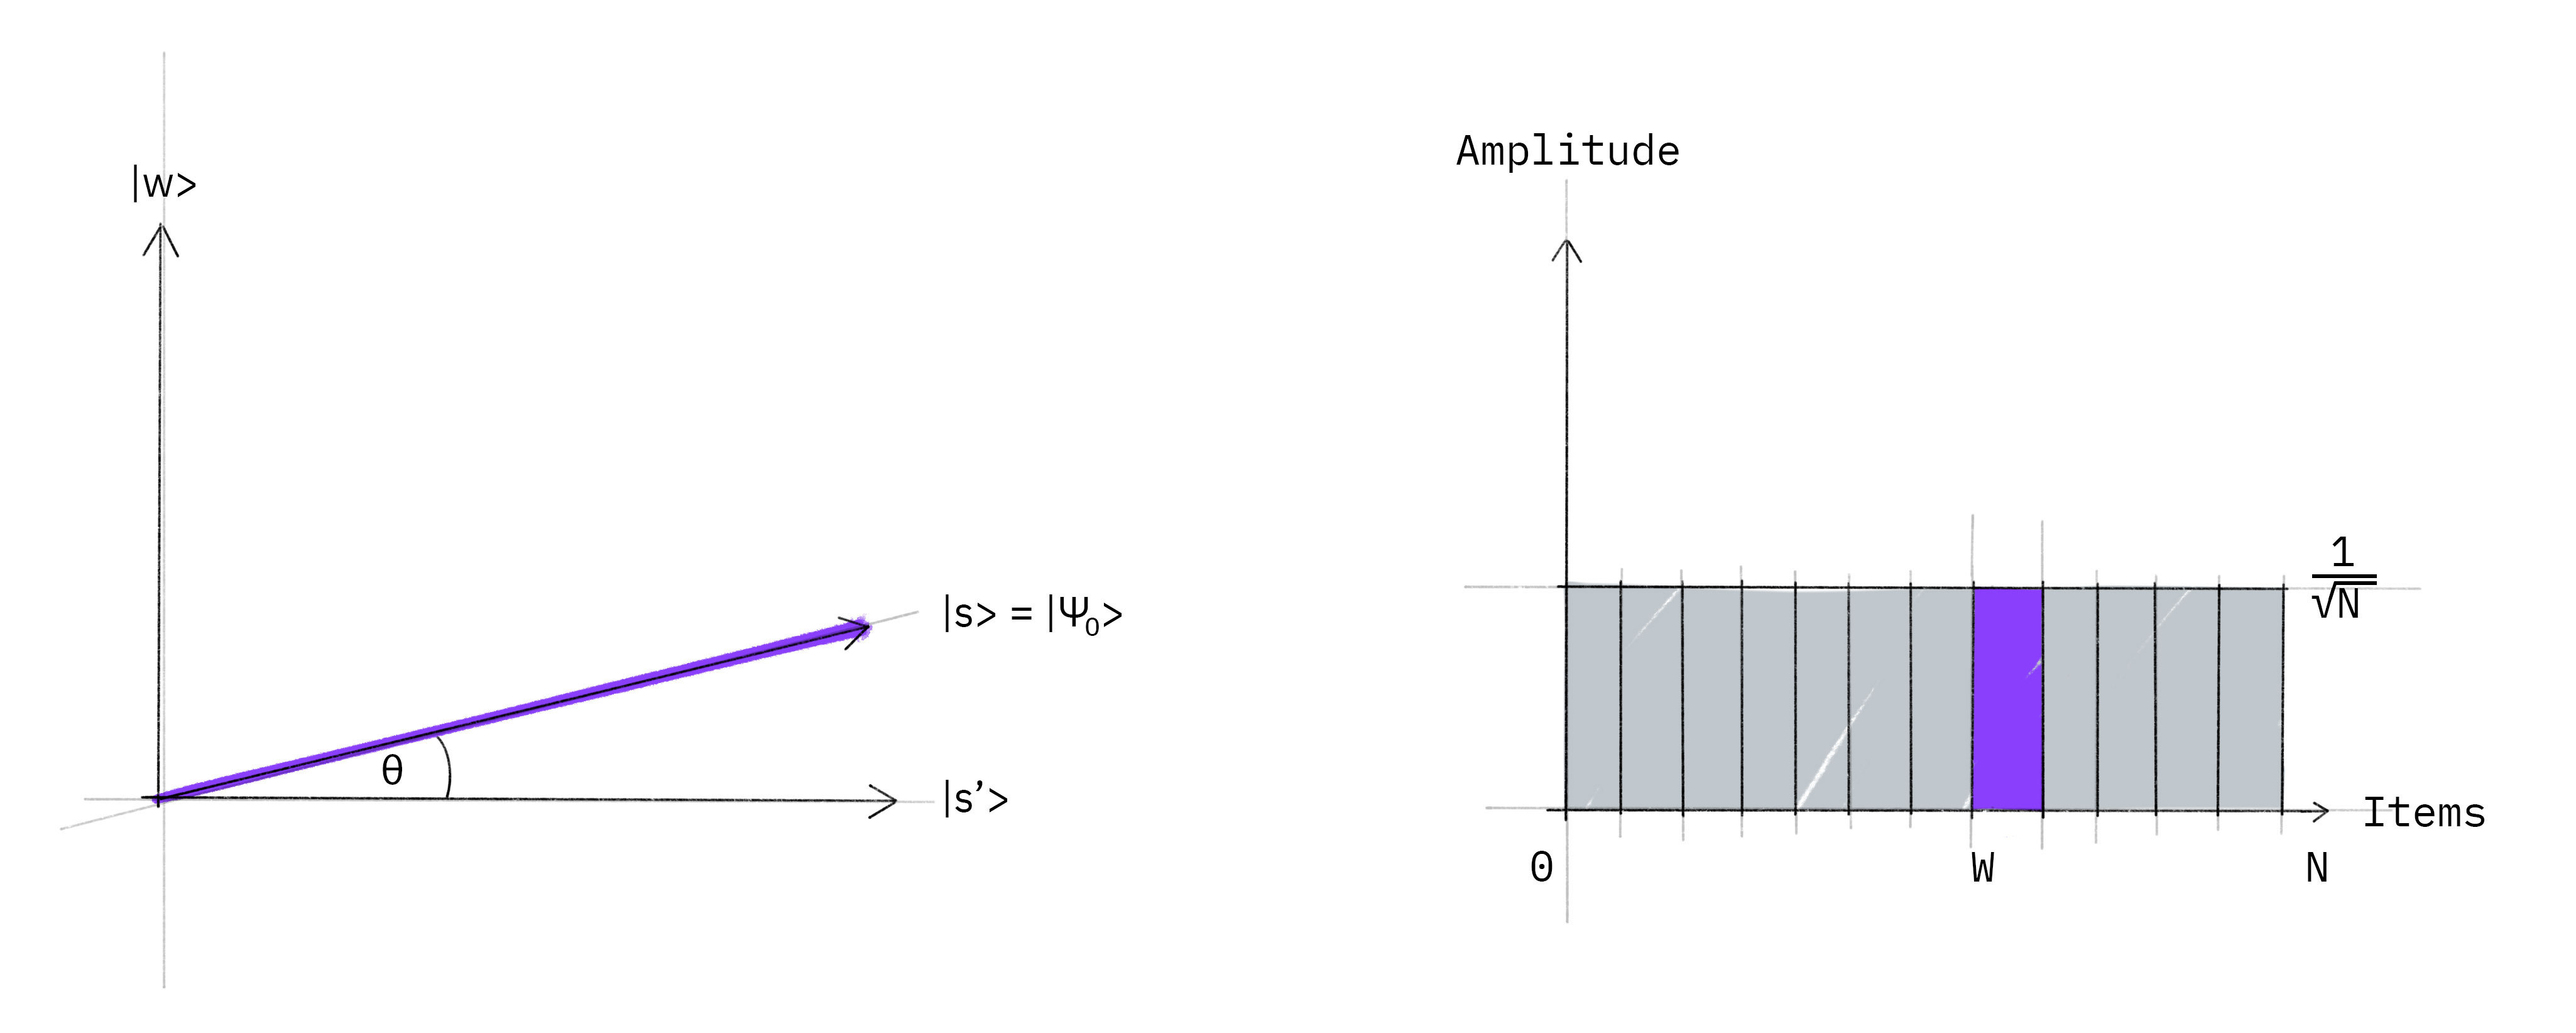

Now:

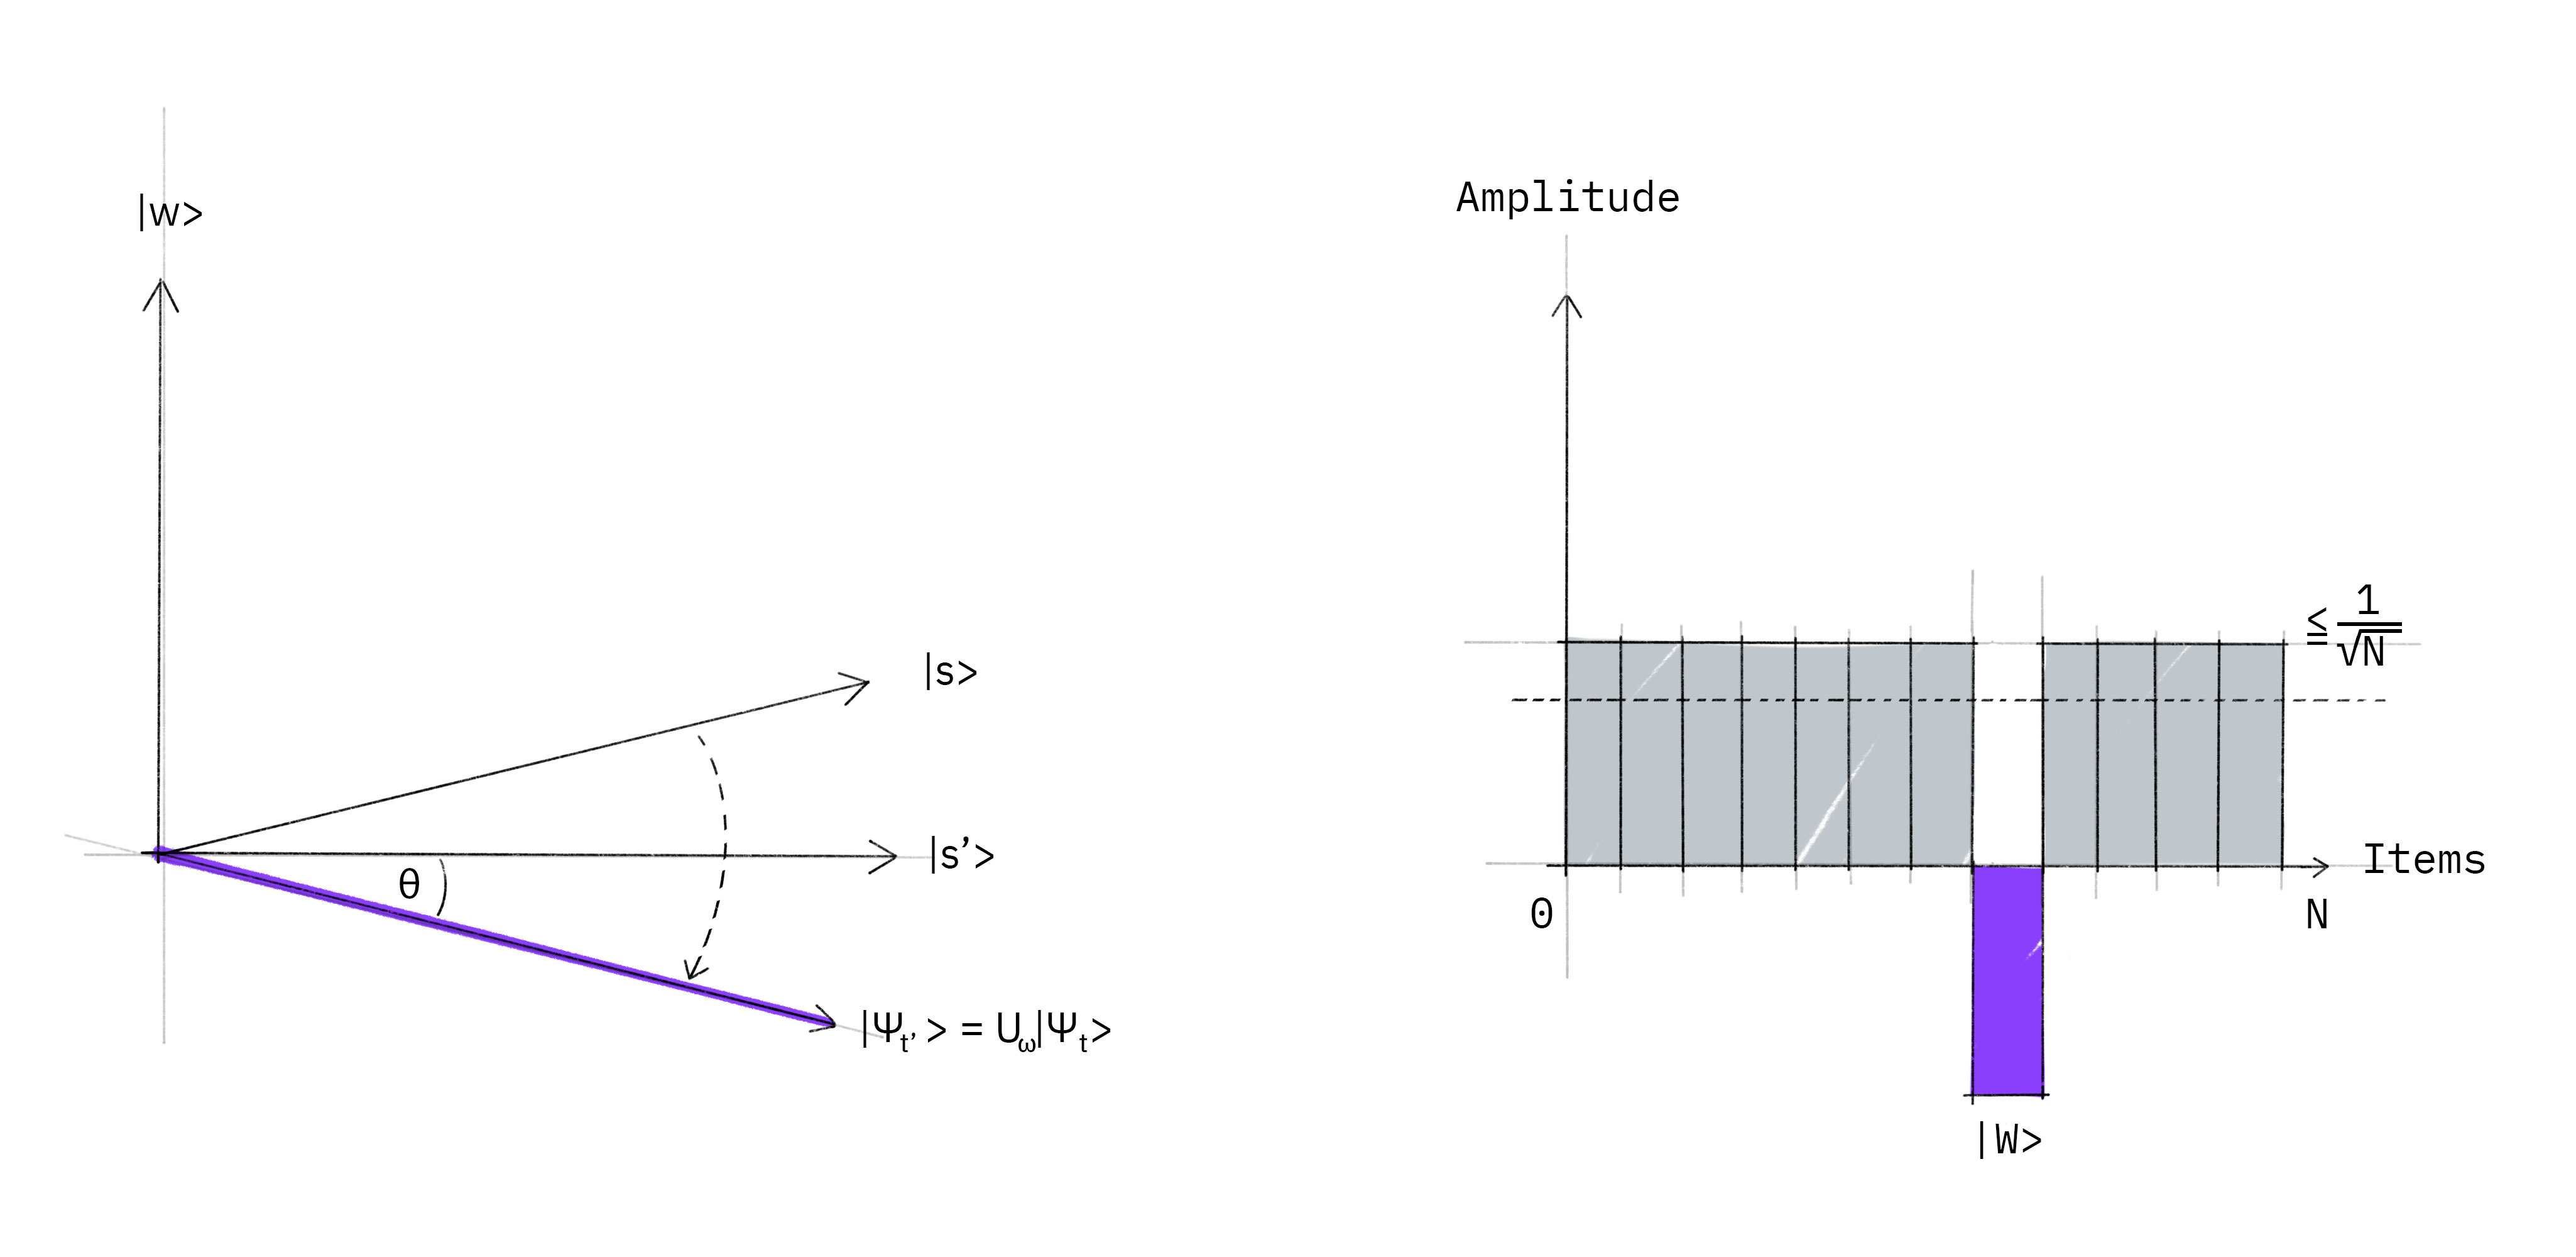


### 4. Diffusion Operator

- After the Oracle, the marked state has a negative phase.

- The Diffuser converts this phase difference into a probability increase.

- Mathematically: $$D=2|s\rangle\langle s|-I$$ where $$|s\rangle=\frac1{\sqrt N}\sum_x |x\rangle$$

- This operation performs an inversion about the average amplitude.

#### How the Code Implements the Diffuser

The diffuser is built using

```python
add_diffusion_operator(num_qubits)
```

**Step 1: Apply Hadamard Gates**

```python
qc.h(...)
```

- This transforms $$|s\rangle\rightarrow|0\rangle^{\otimes n}$$


**Step 2: Apply X Gates**

```python
qc.x(...)
```

- This transforms $$|0\rangle^{\otimes n}\rightarrow|1\rangle^{\otimes n}$$

**Step 3: Apply Multi-Controlled Phase Flip**

```python
qc.h(last)
qc.mcx(...)
qc.h(last)
```

- This applies $$|111...1\rangle\rightarrow - |111...1\rangle$$ which is equivalent to $$2|0...0\rangle\langle0...0|-I$$ after reversing the basis transformation.


**Step 4: Undo $X$ Gates**

```python
qc.x(...)
```

**Step 5: Undo Hadamards**

```python
qc.h(...)
```

- The overall operation becomes $$D=H^{\otimes n}X^{\otimes n}(2|11...1\rangle\langle11...1|-I)X^{\otimes n}H^{\otimes n}$$ which simplifies to $$ D=2|s\rangle\langle s|-I$$

Earlier:

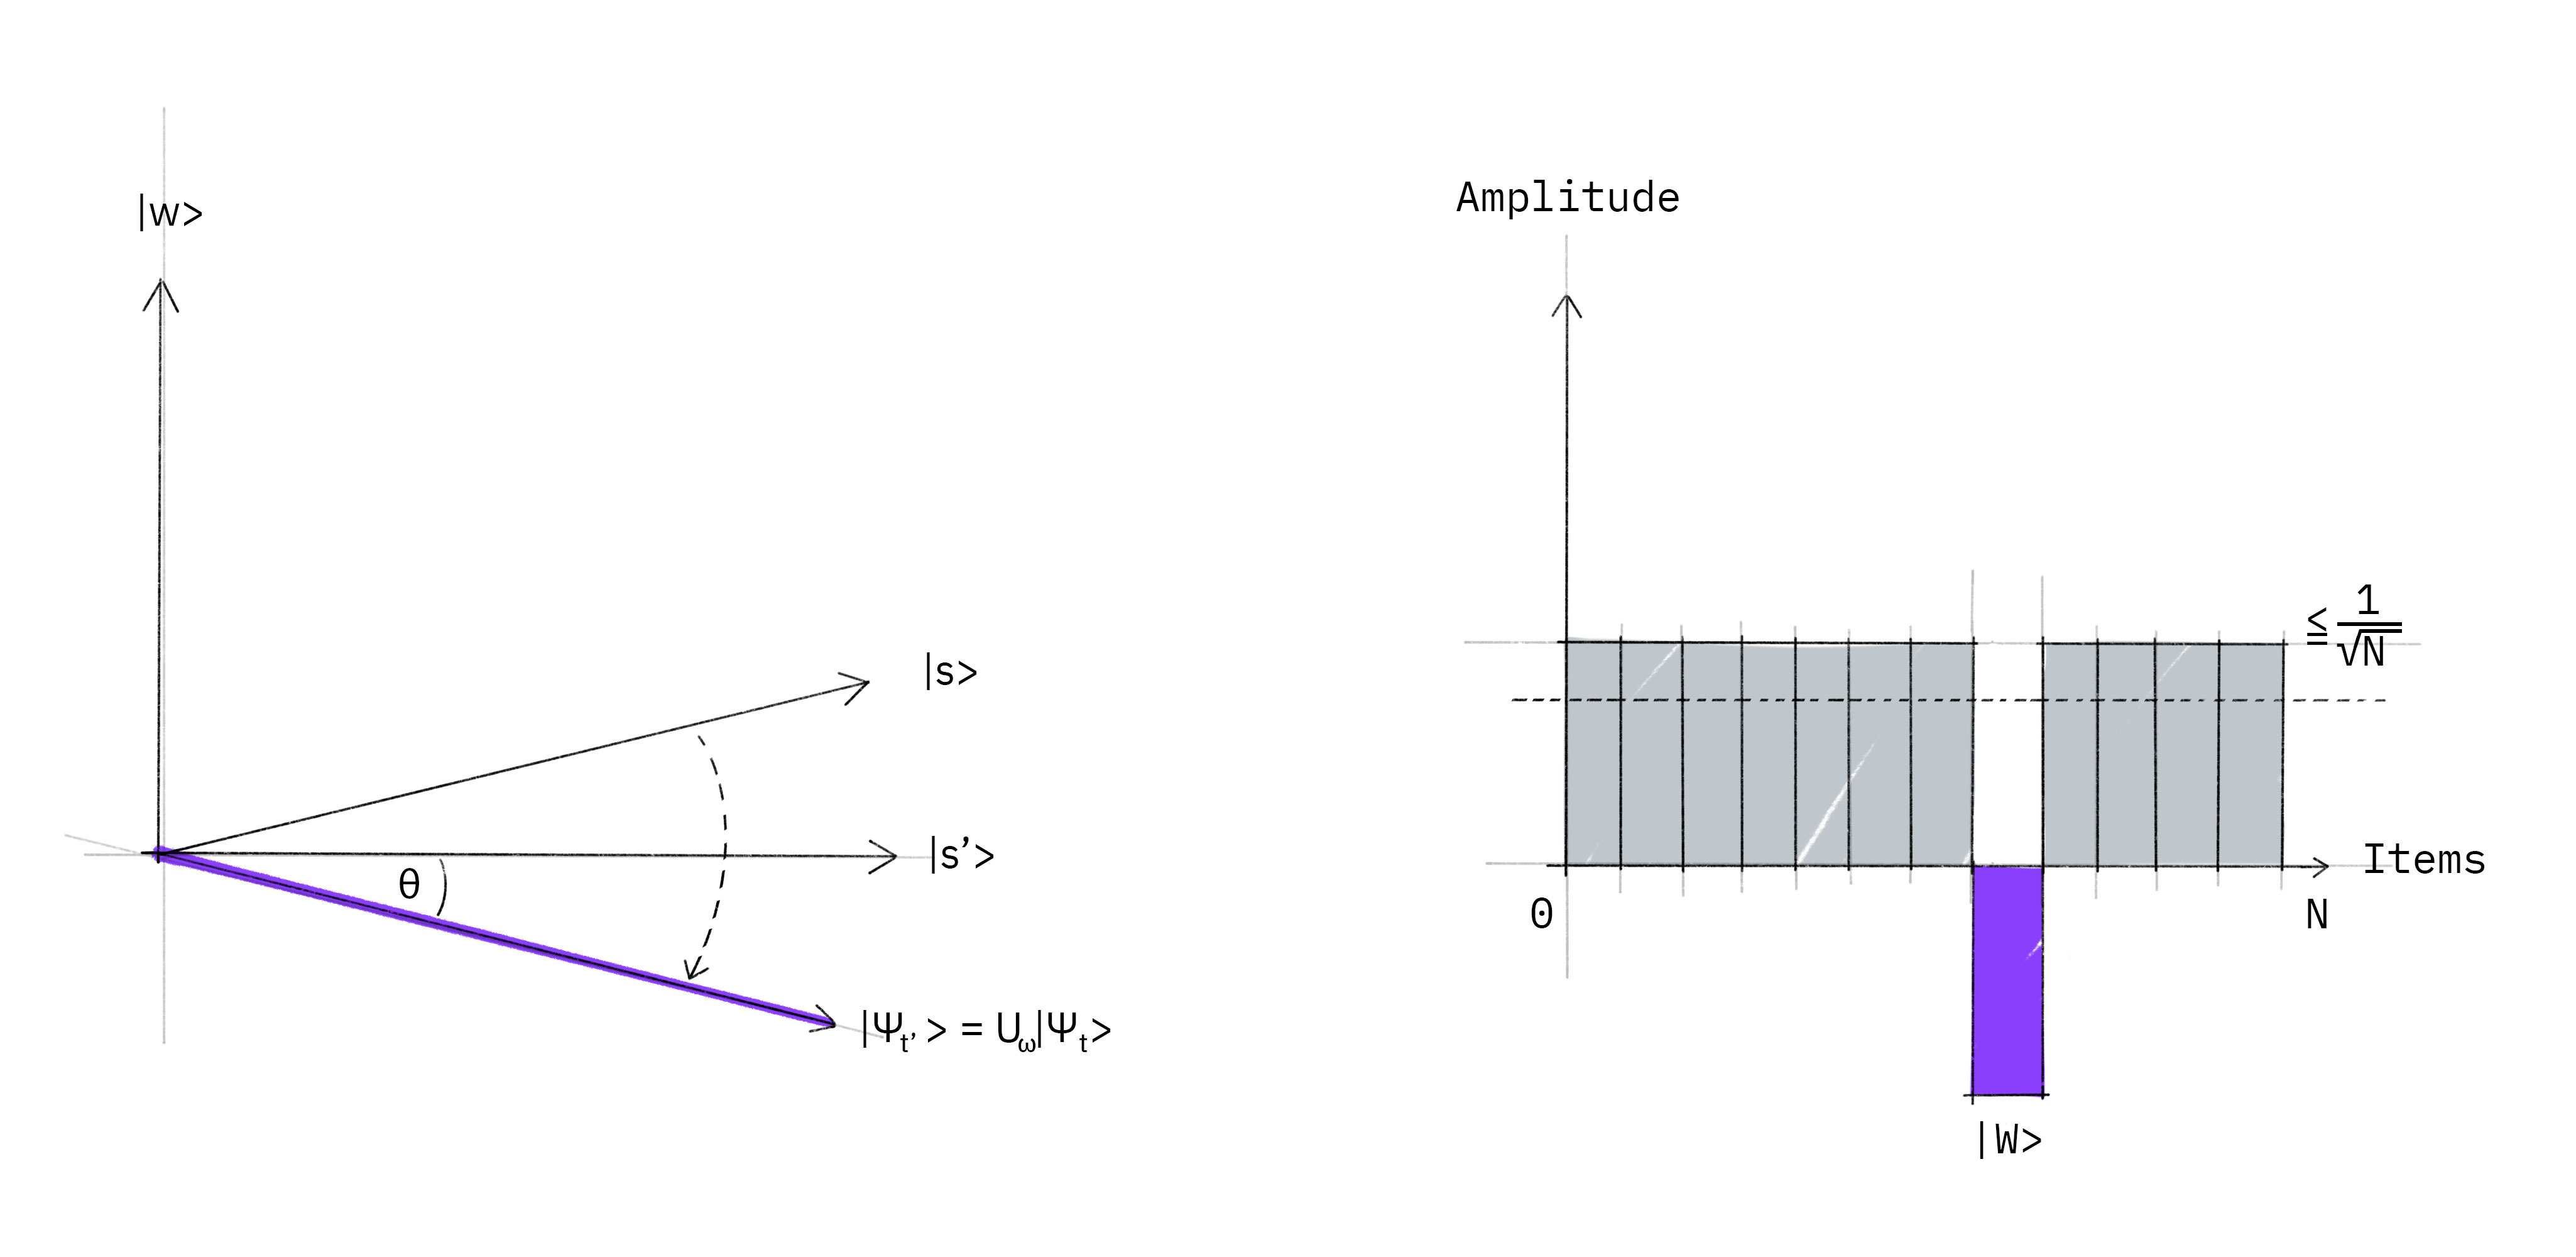

Now:

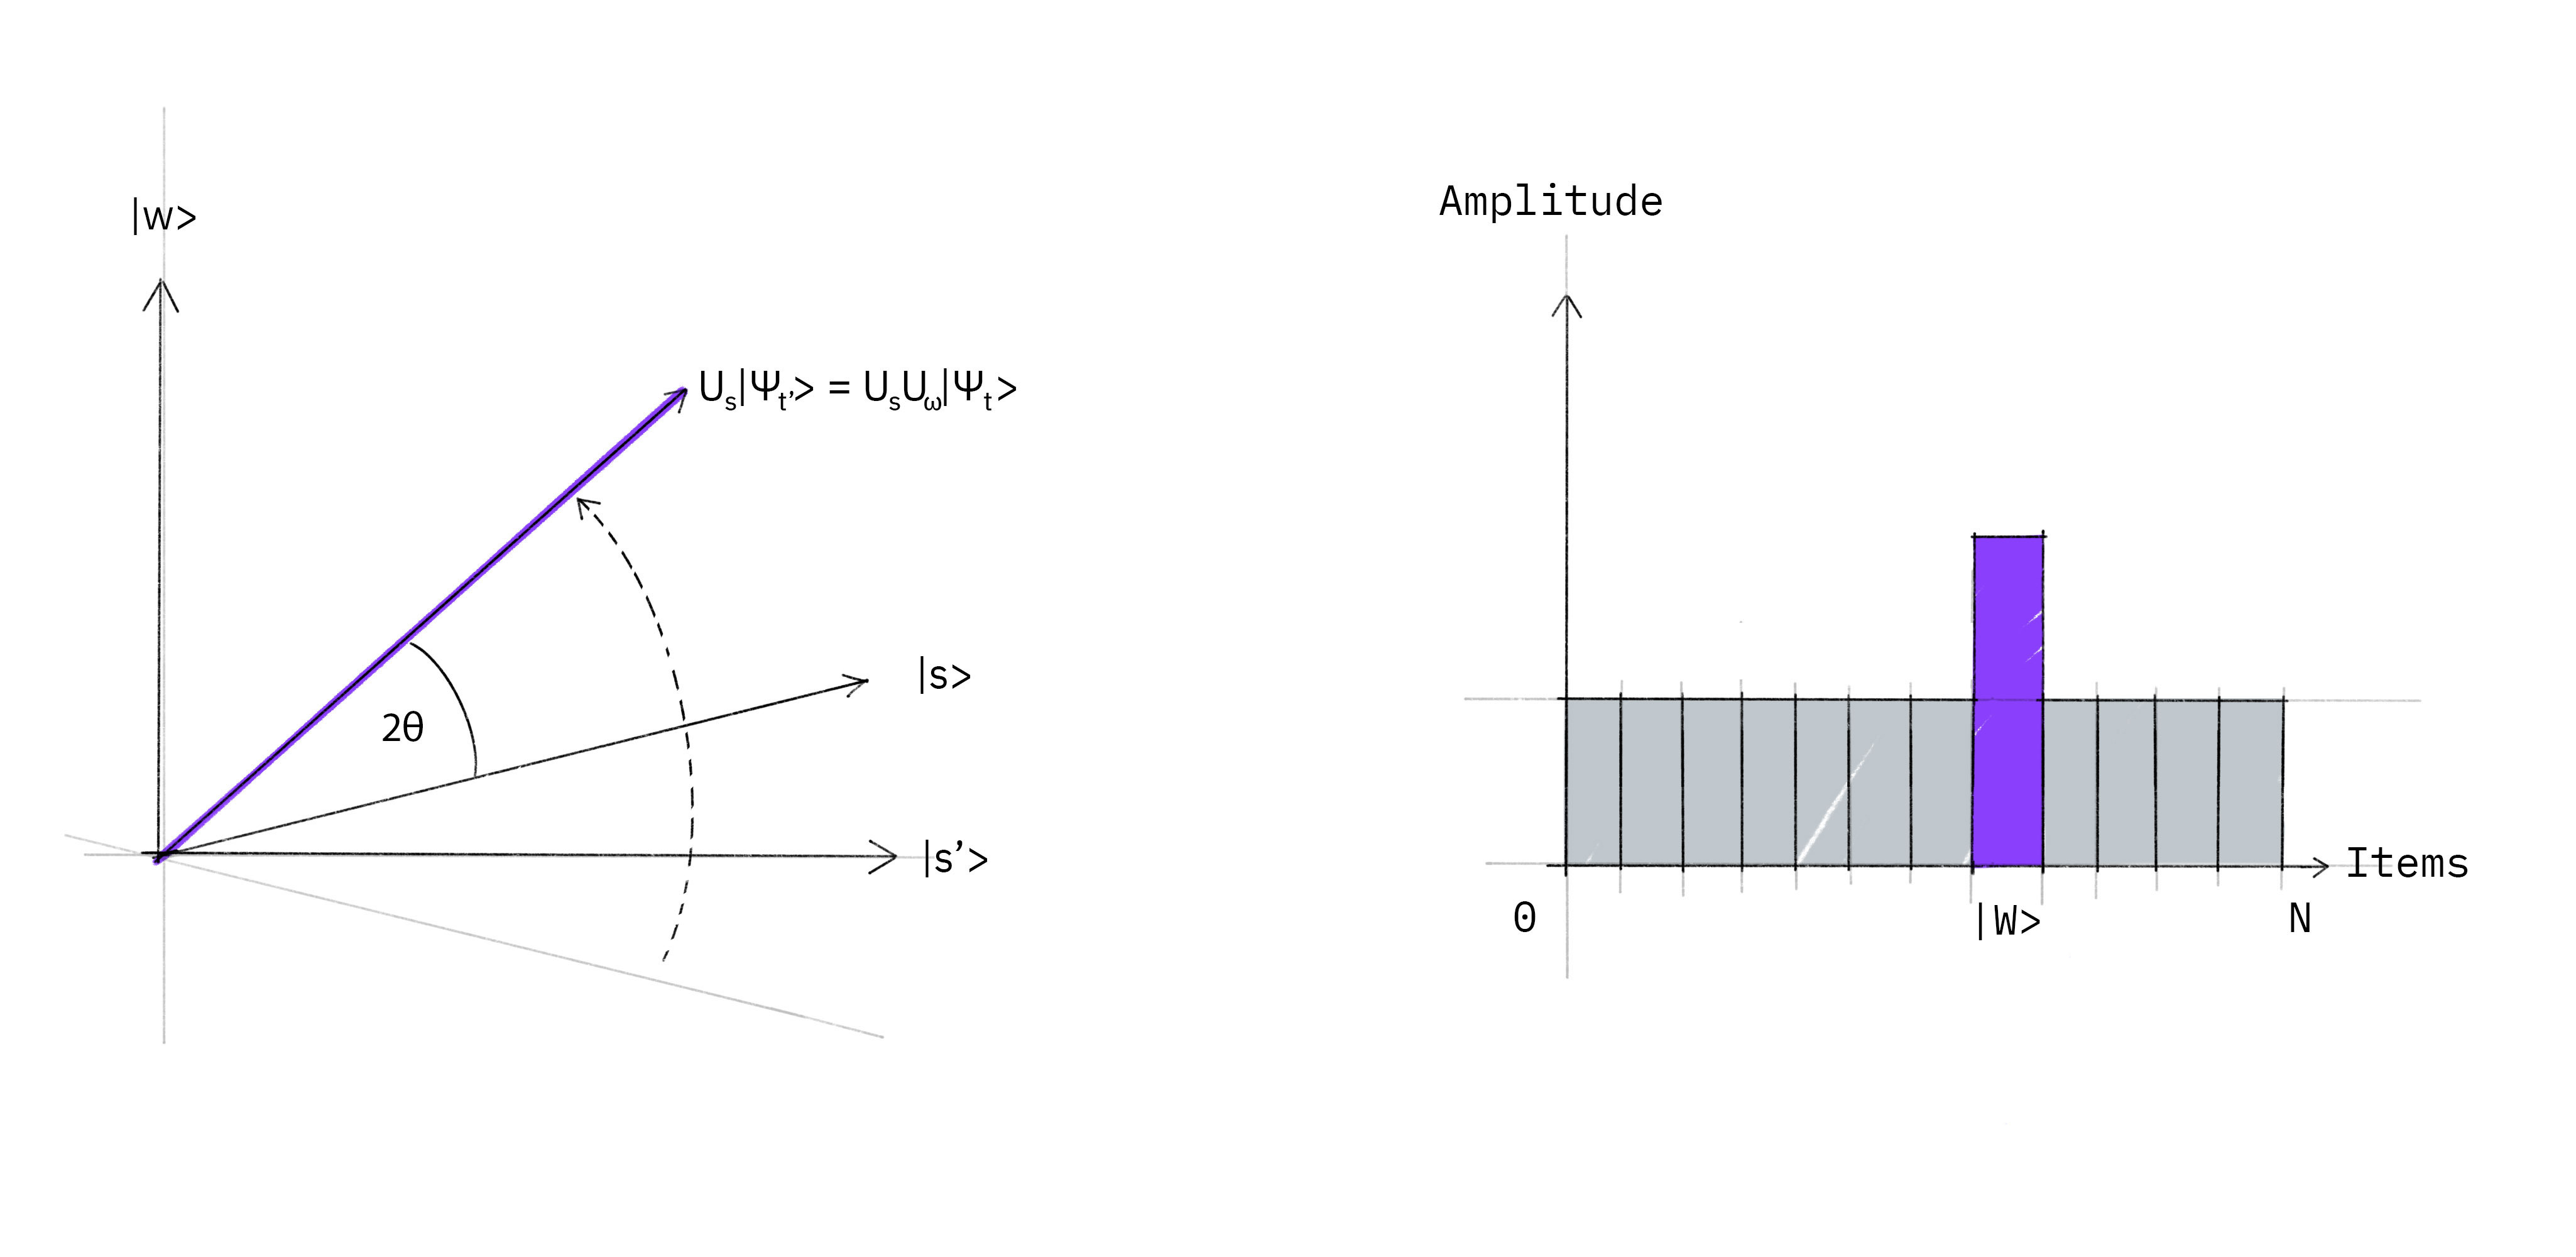

## CODE for Grover's Search:

In [ ]:
# saved circuits for display
QC_ = None
grover_oracle = None
diffusion_operator = None

def GroversSearch(num_qubits, marked_item, n_iterations):

    # allocate qubits
    qr = QuantumRegister(num_qubits);
    cr = ClassicalRegister(num_qubits);
    qc = QuantumCircuit(qr, cr, name=f"grovers-{num_qubits}-{marked_item}")

    # Start with Hadamard on all qubits
    for i_qubit in range(num_qubits):
        qc.h(qr[i_qubit])

    # loop over the estimated number of iterations
    for _ in range(n_iterations):

        qc.barrier()
        print(f"{_}-Oracle")
        # add the grover oracle
        qc.append(add_grover_oracle(_,num_qubits, marked_item).to_instruction(), qr)
        print(f"{_}-Diffusor")
        # add the diffusion operator
        qc.append(add_diffusion_operator(_,num_qubits).to_instruction(), qr)

    qc.barrier()

    # measure all qubits
    qc.measure(qr,cr)

    # return a handle on the circuit
    return qc

############## Grover Oracle

def add_grover_oracle(count,num_qubits, marked_item):
    global grover_oracle

    marked_item_bits = format(marked_item, f"0{num_qubits}b")[::-1]

    qr = QuantumRegister(num_qubits); qc = QuantumCircuit(qr, name=f"(oracle-{count})")

    for (q, bit) in enumerate(marked_item_bits):
        if not int(bit):
            qc.x(q)

    qc.h(num_qubits - 1)

    qc.mcx([x for x in range(num_qubits - 1)], num_qubits - 1)

    qc.h(num_qubits - 1)

    qc.barrier()

    for (q, bit) in enumerate(marked_item_bits):
        if not int(bit):
            qc.x(q)

    if grover_oracle == None or num_qubits <= 5:
        if num_qubits < 9: grover_oracle = qc

    display(qc.draw("mpl"))

    return qc

############## Grover Diffusion Operator

def add_diffusion_operator(count,num_qubits):
    global diffusion_operator

    qr = QuantumRegister(num_qubits); qc = QuantumCircuit(qr, name=f"(diffuser-{count})")

    for i_qubit in range(num_qubits):
        qc.h(qr[i_qubit])
    for i_qubit in range(num_qubits):
        qc.x(qr[i_qubit])
    qc.h(num_qubits - 1)

    qc.mcx([x for x in range(num_qubits - 1)], num_qubits - 1)

    qc.h(num_qubits - 1)

    qc.barrier()

    for i_qubit in range(num_qubits):
        qc.x(qr[i_qubit])
    for i_qubit in range(num_qubits):
        qc.h(qr[i_qubit])

    if diffusion_operator == None or num_qubits <= 5:
        if num_qubits < 9: diffusion_operator = qc

    display(qc.draw("mpl"))

    return qc

Marked Item      : 5
Number of Qubits : 3
Search Space N   : 8
Grover Iterations: 2
0-Oracle


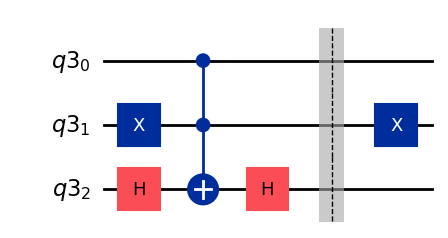

0-Diffusor


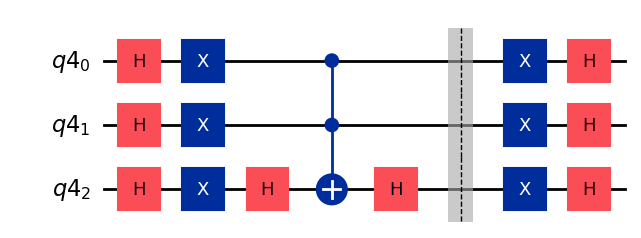

1-Oracle


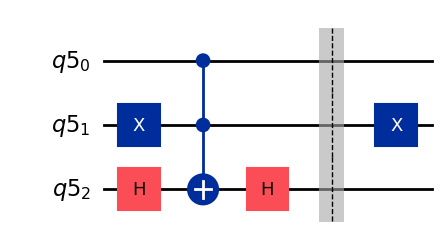

1-Diffusor


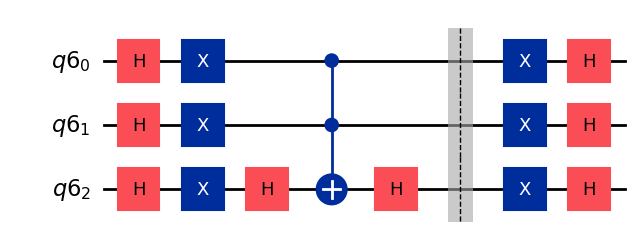

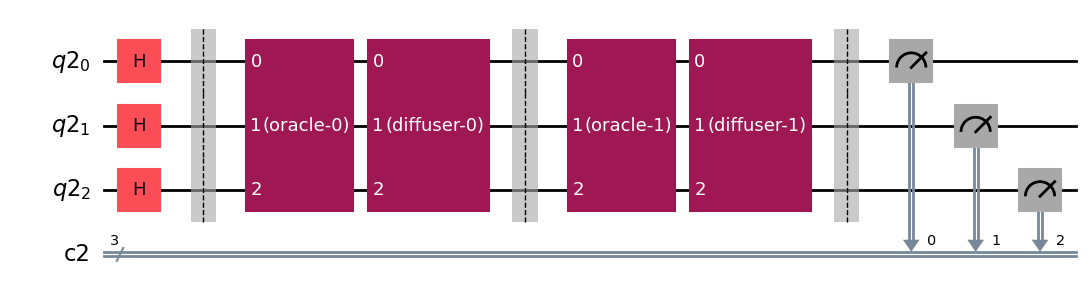

In [ ]:
import math

# User enters the number to search
marked_item = 5

# Determine minimum qubits required
num_qubits = max(1, math.ceil(math.log2(marked_item + 1)))

# Total search space
N = 2 ** num_qubits

# Optimal Grover iterations
n_iterations = max(1,round((math.pi / 4) * math.sqrt(N)))

print(f"Marked Item      : {marked_item}")
print(f"Number of Qubits : {num_qubits}")
print(f"Search Space N   : {N}")
print(f"Grover Iterations: {n_iterations}")

# Build circuit
qc = GroversSearch(num_qubits=num_qubits,marked_item=marked_item,n_iterations=n_iterations)

display(qc.draw("mpl"))

Result(backend_name='aer_simulator', backend_version='0.17.2', job_id='c6122eb5-b11d-465d-9b0a-6a4af827695f', success=True, results=[ExperimentResult(shots=1000, success=True, meas_level=2, data=ExperimentResultData(counts={'0x6': 8, '0x4': 8, '0x2': 8, '0x0': 12, '0x7': 8, '0x3': 7, '0x5': 938, '0x1': 11}), header={'creg_sizes': [['c2', 3]], 'global_phase': 0.0, 'memory_slots': 3, 'n_qubits': 3, 'name': 'grovers-3-5', 'qreg_sizes': [['q2', 3]], 'metadata': {}}, status=DONE, seed_simulator=3785296021, metadata={'time_taken': 0.00059461, 'num_bind_params': 1, 'parallel_state_update': 24, 'parallel_shots': 1, 'required_memory_mb': 1, 'input_qubit_map': [[2, 2], [1, 1], [0, 0]], 'method': 'statevector', 'device': 'CPU', 'num_qubits': 3, 'sample_measure_time': 0.000167186, 'active_input_qubits': [0, 1, 2], 'num_clbits': 3, 'remapped_qubits': False, 'runtime_parameter_bind': False, 'max_memory_mb': 63971, 'noise': 'ideal', 'measure_sampling': True, 'batched_shots_optimization': False, 'fusi

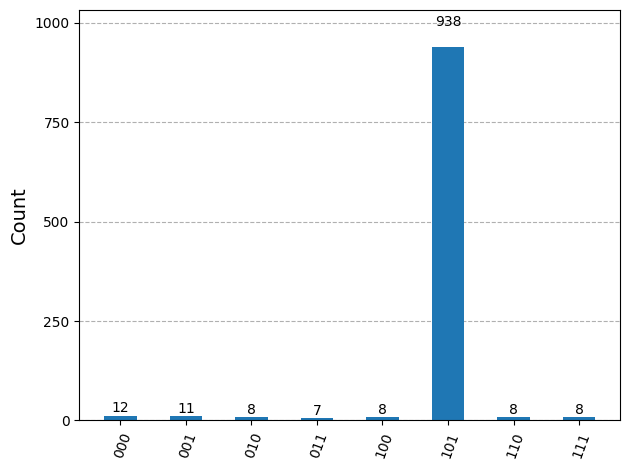

In [ ]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Select Backend
backend = AerSimulator()

qc = qc.decompose()

from qiskit import transpile

tqc = transpile(qc,backend)
#display(tqc.draw("mpl"))

# Execute Circuit
job = backend.run(tqc, shots=1000)

# Get Results
result = job.result()
print(result)
counts = result.get_counts()

print("Measurement Counts:")
print(counts)
plot_histogram(counts)